# Reproducibilidad del estudio de mortalidad esperada en México

**Evaluación comparativa y aplicación al cáncer de mama · Cuaderno para investigación médica**

Este notebook presenta los métodos y resultados del estudio de mortalidad esperada en México y su aplicación al cáncer de mama. Permite seguir cómo se obtienen sus resultados desde los datos procesados y pronósticos distribuidos. Conserva **12 figuras y 45 tablas**, contando las subdivisiones como tablas independientes, con sus salidas visibles para leerlo sin ejecutar código.

La pregunta central es si los modelos de inteligencia artificial mejoran la estimación de la mortalidad esperada y la detección de aumentos, y cómo se comporta esa referencia en cáncer de mama. El estudio es ecológico: sus resultados describen poblaciones y series de tiempo; no estiman efectos causales ni riesgos individuales.

**Cómo leerlo.** Recorra las explicaciones, figuras y tablas; abra los apartados desplegables si necesita más detalle. Para reproducir los cálculos use **Kernel → Restart Kernel and Run All Cells** en el entorno indicado abajo. Se crea una carpeta nueva en cada ejecución. Las salidas ya guardadas muestran una ejecución anterior; al ejecutar se sustituyen por los resultados nuevos.

**Alcance.** Se recalculan métricas, intervalos, detección y análisis C50 disponibles. Los pronósticos originales, las etapas de entrenamiento y ciertas tablas auxiliares son insumos guardados. Cada producto indica **recalculado**, **regenerado desde resultados guardados** o **documental**. La ausencia de una etapa original se declara; un error nunca se reemplaza silenciosamente por referencias.

<a id="indice"></a>
## Índice

1. [Contexto, diseño y vocabulario](#contexto)
2. [Preparar y verificar la ejecución](#preparacion)
3. [Comparación de modelos y detección](#benchmark)
4. [Aplicación al cáncer de mama](#mama)
5. [Tendencia y lugar de defunción](#exploratorios)
6. [APVP y tamaño de localidad](#apvp)
7. [Análisis complementarios y suplemento](#suplemento)
8. [Comprobaciones, procedencia y límites](#balance)

<a id="contexto"></a>
## 1. Contexto, diseño y vocabulario

Se comparan diez métodos en **2 870 series mensuales**, de enero de 2012 a diciembre de 2024, agrupadas por causa, sexo, entidad y edad. Los periodos de validación terminan antes de 2020; el pronóstico aplicado al periodo pandémico comienza en diciembre de 2019. La aplicación C50 considera mujeres de **20 años o más**.

La comparación reúne cuatro modelos clásicos, dos modelos globales entrenados con las series mexicanas, tres modelos fundacionales sin adaptación local y un ensamble por mediana. La aplicación a mama utiliza ocho métodos y excluye LightGBM y N-HiTS. Las implementaciones no son idénticas: véase la tabla S13.

| Término | Lectura práctica |
|---|---|
| Mortalidad esperada | Pronóstico bajo la continuación de los patrones previos a la pandemia. |
| WQL | Error de los cuantiles pronosticados; un valor menor indica mejor pronóstico. |
| Cobertura | Porcentaje de observaciones dentro del intervalo de predicción. |
| IP | Intervalo de predicción: incertidumbre sobre observaciones futuras; el 90 % de mama es nominal. |
| IC | Intervalo de confianza de parámetros o medias ajustadas; no es un IP. |
| TEE | Tasa estandarizada por edad, por 100 000 mujeres-año. |
| MASE | Error absoluto escalado con el ingenuo estacional del entrenamiento; < 1 no prueba superioridad en la prueba. |
| APVP | Años potenciales de vida perdidos antes de los 75 años. |
| pp | Puntos porcentuales: diferencia absoluta entre porcentajes. |

Los análisis de tendencia, lugar y APVP son exploratorios y posteriores a los resultados predictivos. La figura 1 se genera después de preparar los datos, en la sección 3.

<a id="preparacion"></a>
## 2. Preparar y verificar la ejecución

Se necesitan los dos paquetes de datos de la [guía de descarga](../docs/DESCARGA_Y_EJECUCION.md), extraídos bajo `data/external/`. No se descarga nada al ejecutar este notebook. Las referencias se conservan intactas.

Prepare una vez los entornos desde la raíz del repositorio:

```bash
python3.11 -m venv .venv-benchmark-reproduccion
.venv-benchmark-reproduccion/bin/python -m pip install -r environments/benchmark-recalculo.txt
python3.12 -m venv .venv-notebook
.venv-notebook/bin/python -m pip install -r environments/notebook.txt
.venv-notebook/bin/python -m jupyterlab notebooks/reproducibilidad_manuscrito.ipynb
```

Seleccione el kernel de `.venv-notebook`. En Windows los ejecutables están en `Scripts/python.exe`. Las celdas comprueban las versiones reales de ambos entornos; no basta con que exista una carpeta con el nombre esperado.

<details><summary>Tiempo, archivos de salida y repetición</summary>

El repositorio documenta aproximadamente un minuto para el benchmark y cuatro para C50 en el equipo original; la duración en otro equipo puede variar. Se mantienen 10 000 simulaciones y dos hilos. Cada reinicio y ejecución completa crea un directorio distinto bajo `ejecuciones/figuras_revision/`; no se sobrescriben ejecuciones anteriores. Para repetir una etapa ya ejecutada, reinicie el kernel y ejecute todo. Los registros completos quedan en la carpeta de salida.

El notebook usa el entorno C50 para leer y representar datos. El benchmark corre en un proceso independiente con sus versiones históricas de NumPy y pandas. No se instalan dependencias desde las celdas.
</details>

In [1]:
from pathlib import Path
import os
import sys

# Detectar la raíz desde la raíz del proyecto o desde notebooks/.
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "scripts/gmm.py").is_file()), None)
if REPO is None:
    raise FileNotFoundError("Abra este notebook desde el repositorio mortalidad-mexico-ia.")
sys.path.insert(0, str(REPO / "notebooks"))
from soporte_reproducibilidad import (
    MIEMBROS, comprobar_entornos, nueva_ejecucion, ejecutar, instantanea_entradas,
    cargar_json, guardar_json, sha256, actualizar_rotulos, catalogo_tablas,
    mostrar_tabla, mostrar_figura, cerrar_reproduccion,
)
import numpy as np
import pandas as pd
from IPython.display import display, HTML, Markdown

# Parámetros que puede adaptar el lector.
DATOS = REPO / "data/external"
BASE_SALIDAS = REPO / "ejecuciones/figuras_revision"
PYTHON_C50 = Path(sys.executable)
python_rel = "Scripts/python.exe" if os.name == "nt" else "bin/python"
PYTHON_BENCHMARK = Path(os.environ.get(
    "GMM_PYTHON_BENCHMARK", str(REPO / ".venv-benchmark-reproduccion" / python_rel)
))
NSIM, HILOS = 10_000, 2
versiones, entornos = comprobar_entornos(REPO, PYTHON_BENCHMARK, PYTHON_C50)
display(versiones)

,Entorno,Paquete,Versión
0,benchmark,Python,3.11.17
1,benchmark,numpy,2.4.6
2,benchmark,pandas,2.3.3
3,benchmark,scipy,1.17.1
4,benchmark,statsmodels,0.15.0
5,C50 / notebook,Python,3.12.3
6,C50 / notebook,numpy,2.3.5
7,C50 / notebook,pandas,2.2.3
8,C50 / notebook,scipy,1.18.1
9,C50 / notebook,statsmodels,0.15.0


In [2]:
SALIDA = nueva_ejecucion(REPO, DATOS, BASE_SALIDAS)
guardar_json(SALIDA / "entornos.json", entornos)
# Conservar también las dependencias transitivas efectivamente instaladas.
for nombre, exe in [("benchmark", PYTHON_BENCHMARK), ("notebook", PYTHON_C50)]:
    import subprocess
    freeze = subprocess.check_output([str(exe), "-m", "pip", "freeze"], text=True)
    (SALIDA / f"requirements_ejecutados_{nombre}.txt").write_text(freeze, encoding="utf-8")

ejecutar(REPO, SALIDA, "verificar_inicio", [
    PYTHON_BENCHMARK, REPO / "scripts/gmm.py", "verificar", "--data-dir", DATOS,
])
antes = instantanea_entradas(REPO, DATOS)
inventario = []
print("Salida de esta ejecución:", Path(os.path.relpath(SALIDA, REPO)))

verificar_inicio: en ejecución…


verificar_inicio: código 0; 0.64 s. Registro completo en logs_notebook/.


Resultados de referencia: 113/113 archivos íntegros
Entradas en --data-dir: 109/109 archivos íntegros
NPZ: 108 matrices revisadas (9 modelos × 12 archivos esperados = 108); el ensamble se calcula desde los miembros.
Corpus: 2 870 series × 156 meses (2012-2024), finitos y no negativos.
PASS
Nota: este nivel comprueba integridad y formato; no constituye validación científica.
Salida de esta ejecución: ejecuciones/figuras_revision/20261020T172839Z_5c70e4a4


La verificación comprueba integridad, dimensiones y valores finitos; no constituye validación científica. El corpus esperado contiene **2 870 × 156 observaciones** y los NPZ guardan nueve modelos; el ensamble se calcula con sus seis miembros.

<a id="benchmark"></a>
## 3. Comparación de modelos y detección

### Recalcular los resultados y generar las figuras

La validación utiliza orígenes en diciembre de 2014, 2015 y 2016 a 36 meses, y dos orígenes a 48 meses. El detector D1 mantiene separados los periodos para calcular umbrales, ajustar falsas alarmas y evaluar la detección. Estos pasos, junto con intervalos y sensibilidades, se ejecutan en el orden definido por el repositorio.

Primero recalculamos benchmark y C50. Después el comando de referencia `gmm.py figuras` recibe **esas salidas nuevas**. Las figuras incluyen insumos de etapas originales guardadas, identificados en sus notas; no son fotografías extraídas del manuscrito.

In [3]:
# Benchmark: métricas y análisis desde los pronósticos guardados.
ejecutar(REPO, SALIDA, "benchmark", [
    PYTHON_BENCHMARK, REPO / "scripts/gmm.py", "benchmark",
    "--data-dir", DATOS, "--output-dir", SALIDA / "benchmark",
])
# Este paso independiente no forma parte de gmm.py benchmark.
ejecutar(REPO, SALIDA, "reconstruir_S1_S2A", [
    PYTHON_BENCHMARK, REPO / "src/benchmark/analisis/reconstruir_S1_S2A.py",
    "--data-dir", DATOS, "--output-dir", SALIDA / "reconstruccion",
])
# Una diferencia de comparación se conserva y se examina en el balance final.
ejecutar(REPO, SALIDA, "comparar_benchmark", [
    PYTHON_BENCHMARK, REPO / "scripts/gmm.py", "comparar",
    "--output-dir", SALIDA / "benchmark",
], codigos=(0, 1))

benchmark: en ejecución…


benchmark: código 0; 46.28 s. Registro completo en logs_notebook/.


reconstruir_S1_S2A: en ejecución…


reconstruir_S1_S2A: código 0; 0.41 s. Registro completo en logs_notebook/.


PASS {"S2A": {"filas": 10, "valores_numericos": 120, "comparacion": {"max_abs": 0.0, "max_rel": 0.0, "n_num": 0, "fallas": []}}, "S1": {"series": 2870, "valores_conteo": 140, "comparacion": {"max_abs": 0.0, "max_rel": 0.0, "n_num": 0, "fallas": []}, "alcance": "Conteos recalculados; Tipo y CIE10 conservados como definiciones de entrada."}, "procedencia": "Reconstrucción independiente de Codex cotejada contra las entradas históricas; no es código histórico recuperado."}
comparar_benchmark: en ejecución…


comparar_benchmark: código 0; 0.28 s. Registro completo en logs_notebook/.


benchmark {'sin_referencia_conocido_verificado': 1, 'identico_bytes': 57, 'difiere_conocido_verificado': 1, 'identico_contenido': 4, 'coincide_tolerancia': 6}
Informe: ./ejecuciones/figuras_revision/20261020T172839Z_5c70e4a4/benchmark/comparacion_referencia.json


0

In [4]:
# C50: reconstrucción de microdatos, tendencia, lugar, APVP y localidad.
ejecutar(REPO, SALIDA, "c50", [
    PYTHON_C50, REPO / "scripts/gmm.py", "c50",
    "--data-dir", DATOS, "--output-dir", SALIDA / "c50",
    "--nsim", str(NSIM), "--hilos", str(HILOS),
])
ejecutar(REPO, SALIDA, "comparar_c50", [
    PYTHON_C50, REPO / "scripts/gmm.py", "comparar",
    "--output-dir", SALIDA / "c50",
], codigos=(0, 1))

c50: en ejecución…


c50: código 0; 278.4 s. Registro completo en logs_notebook/.


comparar_c50: en ejecución…


comparar_c50: código 1; 0.05 s. Registro completo en logs_notebook/.


c50 {'identico_bytes': 12, 'difiere': 4, 'coincide_tolerancia': 25, 'no_generado_conocido_verificado': 1, 'difiere_conocido_verificado': 1}
Informe: ./ejecuciones/figuras_revision/20261020T172839Z_5c70e4a4/c50/comparacion_referencia.json


1

In [5]:
# Comando solicitado, conectado a resultados recién calculados.
ejecutar(REPO, SALIDA, "figuras", [
    PYTHON_C50, REPO / "scripts/gmm.py", "figuras",
    "--data-dir", DATOS, "--output-dir", SALIDA / "figuras",
    "--resultados-benchmark", SALIDA / "benchmark",
    "--resultados-c50", SALIDA / "c50",
])
# Reutilizar los rótulos editoriales del estudio.
# Las comprobaciones exigen conservar los artistas numéricos de los gráficos.
actualizar_rotulos(REPO, SALIDA, PYTHON_C50)
B = SALIDA / "benchmark/benchmark"
C = SALIDA / "c50/c50"
tablas = catalogo_tablas(REPO, SALIDA, DATOS)
print("Figuras listas. Las versiones históricas también se conservan en figuras_base_historica/.")

figuras: en ejecución…


figuras: código 0; 6.12 s. Registro completo en logs_notebook/.


rotulos_F3: en ejecución…


rotulos_F3: código 0; 1.1 s. Registro completo en logs_notebook/.


rotulos_F6_S3: en ejecución…


rotulos_F6_S3: código 0; 0.98 s. Registro completo en logs_notebook/.


rotulos_S1_S2_C50: en ejecución…


rotulos_S1_S2_C50: código 0; 3.87 s. Registro completo en logs_notebook/.


Figuras listas. Las versiones históricas también se conservan en figuras_base_historica/.


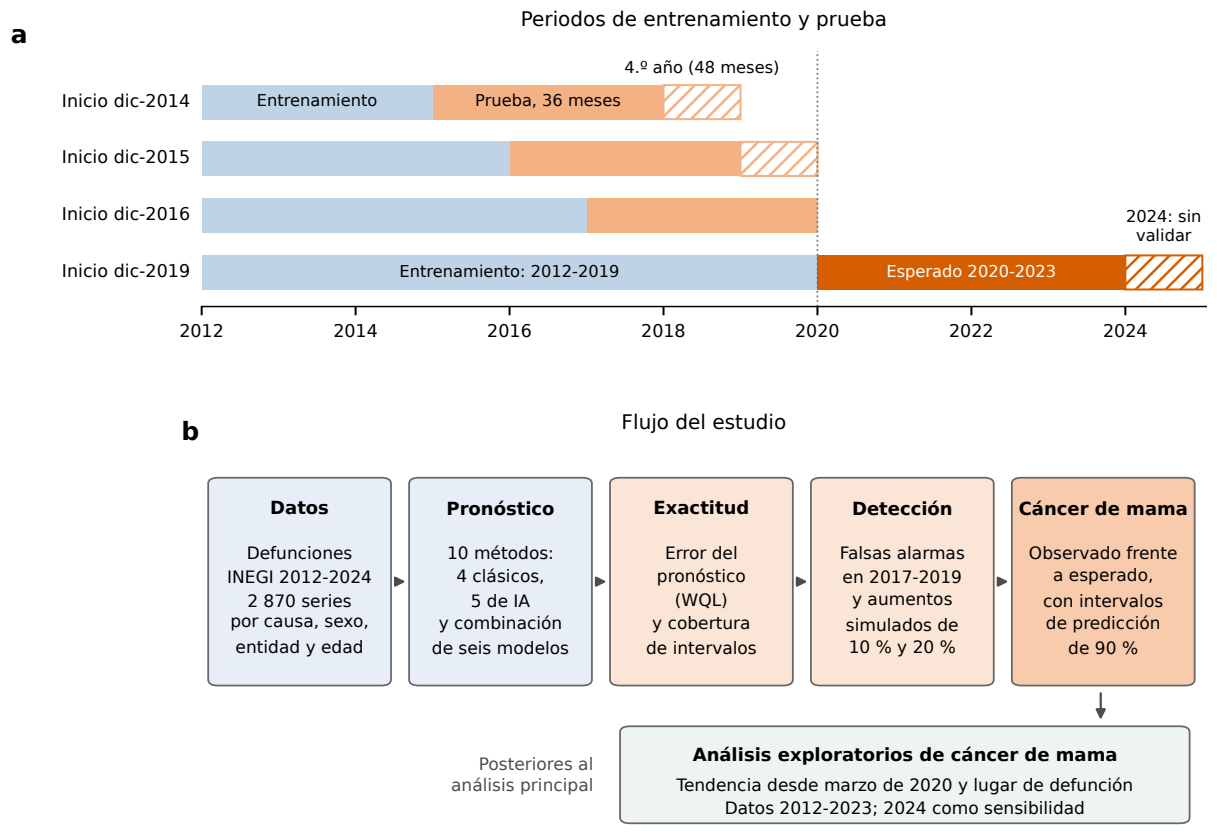

**Figura 1.** Diseño del estudio. a: periodos de entrenamiento y prueba; cada pronóstico utiliza datos del estudio anteriores a su inicio. La validación termina antes de 2020; el tramo rayado indica el cuarto año, evaluado desde 2014 y 2015. La mortalidad esperada se pronosticó desde diciembre de 2019; el quinto año (2024) no tiene validación. b: flujo del análisis, incluidos los estudios exploratorios de tendencia y lugar de defunción realizados después del análisis principal. WQL: pérdida de cuantiles ponderada, medida del error del pronóstico.

In [6]:
inventario.append(mostrar_figura(REPO, SALIDA, '1'))

### Del pronóstico al error: un cálculo visible

El ensamble toma la mediana de seis modelos **por serie, mes y cuantil**. Para los cuantiles 0.1, 0.5 y 0.9, la WQL resume la pérdida asimétrica del pronóstico y la divide entre el volumen observado. La cobertura comprueba si cada observación cae entre los cuantiles 0.1 y 0.9. Las siguientes celdas reproducen estos cálculos para el origen de diciembre de 2016 y los cotejan con la tabla de métricas generada por el benchmark.

In [7]:
corpus = pd.read_csv(DATOS / "benchmark/datos/corpus2_mortalidad_mensual.csv.gz", index_col=0)
assert corpus.shape[0] == 2870
observado = corpus[[str(i) for i in range(60, 96)]].to_numpy(float)  # enero 2017–diciembre 2019
with np.load(DATOS / "benchmark/pronosticos/publicados/fc_2016-12.npz", allow_pickle=False) as z:
    ensamble = np.median(np.stack([z[m] for m in MIEMBROS]), axis=0)
cuantiles = np.array([0.1, 0.5, 0.9])
residuo = observado[..., None] - ensamble
perdida = np.maximum(cuantiles * residuo, (cuantiles - 1) * residuo)
wql = 2 * perdida.sum(axis=(1, 2)) / (3 * np.abs(observado).sum(axis=1) + 1e-9)
cobertura = 100 * ((observado >= ensamble[..., 0]) & (observado <= ensamble[..., 2])).mean(axis=1)
metricas = pd.read_csv(B / "resultados/benchmark/metricas_por_serie.csv.gz")
comparables = metricas[(metricas.model == "Ensamble (mediana)") & (metricas.origin == "2016-12")].set_index("sid").loc[corpus.index]
# El archivo de métricas se escribe con seis decimales: tolerancia de su redondeo.
np.testing.assert_allclose(wql, comparables.WQL, rtol=0, atol=5.01e-7)
np.testing.assert_allclose(cobertura, comparables.cov80, rtol=0, atol=5.01e-7)
display(pd.DataFrame({"Serie": corpus.index[:5], "WQL recalculada": wql[:5], "Cobertura 80 %, %": cobertura[:5]}))

,Serie,WQL recalculada,"Cobertura 80 %, %"
0,Accidentes de tránsito|H|E01|0-39,0.221093,63.888889
1,Accidentes de tránsito|H|E01|Todas,0.157341,80.555556
2,Accidentes de tránsito|H|E02|0-39,0.495165,41.666667
3,Accidentes de tránsito|H|E02|40-64,0.656956,58.333333
4,Accidentes de tránsito|H|E02|Todas,0.624242,33.333333


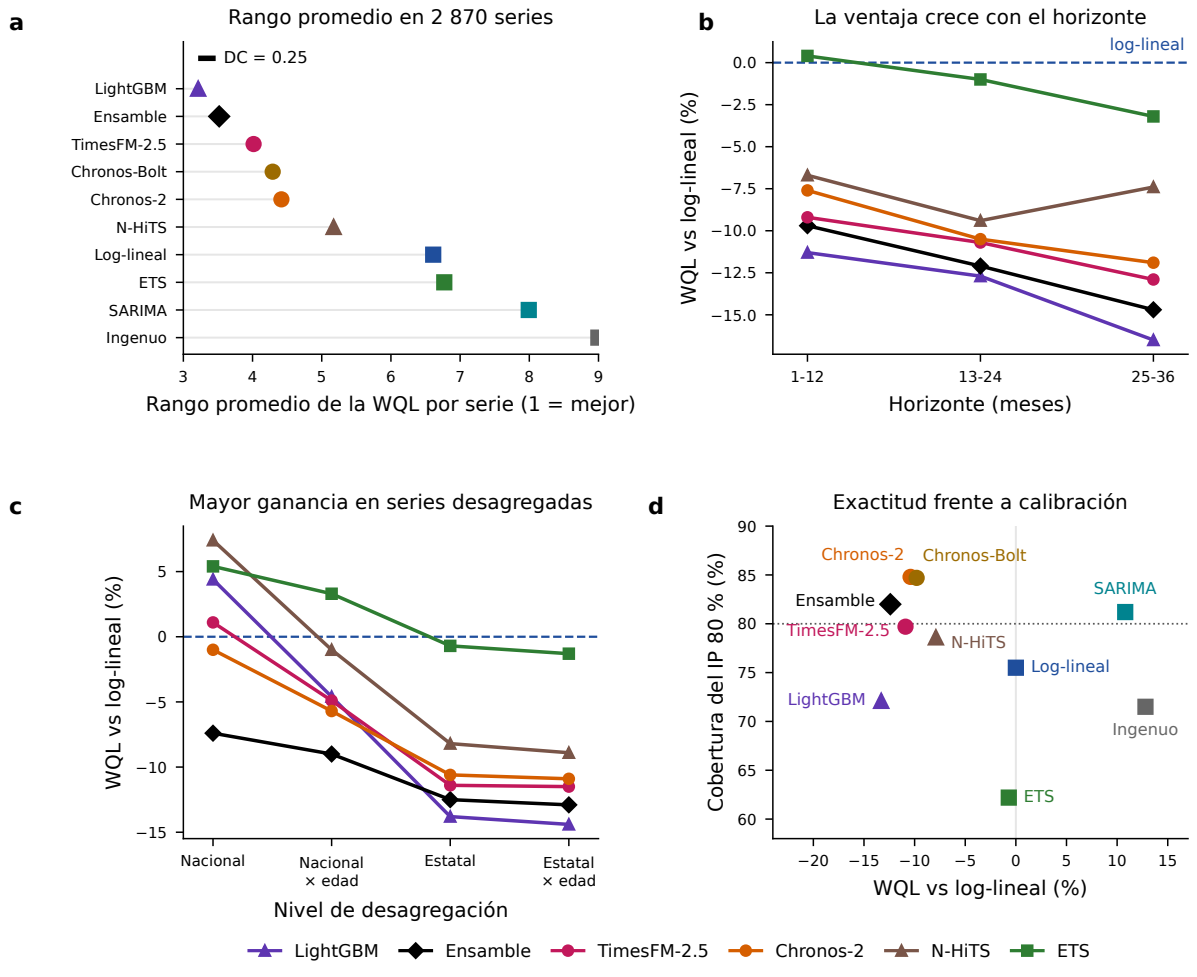

**Figura 2.** Exactitud de diez modelos en 2 870 series mensuales de mortalidad (tres fechas de inicio, con pruebas anteriores a 2020, 36 meses). a: rango promedio de la WQL en cada serie (1 = mejor) y diferencia crítica (DC) de Nemenyi; con 28 conglomerados de causa, DC = 2.56 (tabla S10). b: Error (WQL) relativo al log-lineal por plazo del pronóstico (negativo = menor error). c: Error (WQL) relativo por nivel geográfico y grupo de edad. d: exactitud y proporción de observaciones dentro del intervalo de predicción de 80 % (línea: 80 %). LightGBM y N-HiTS se entrenaron conjuntamente con las series del estudio; Chronos-2 se evaluó sin adaptación local.

In [8]:
inventario.append(mostrar_figura(REPO, SALIDA, '2'))

In [9]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, '1', plegada=False))

Modelo,Familia,Rango (1 = mejor),"Reducción del error frente al log-lineal, % (IC 95 %)",Cobertura del intervalo de 80 % (%),"Falsas alarmas, 2017-2019 (%)",Exceso de 20 % detectado (%)
LightGBM,Global (IA),3.21,13.3 (10.6 a 16.2),72.1,4.1,21.6
Ensamble,Clásicos e IA,3.52,12.4 (9.9 a 14.8),82,4.5,22.2
TimesFM-2.5,Fundacional (IA),4.01,10.9 (6.9 a 14.7),79.7,5.1,23
Chronos-Bolt,Fundacional (IA),4.29,9.8 (5.4 a 13.9),84.7,4.8,22.9
Chronos-2,Fundacional (IA),4.42,10.4 (7.0 a 13.6),84.8,4.5,20.2
N-HiTS,Global (IA),5.17,7.9 (4.6 a 11.4),78.6,4.2,25.7
Log-lineal,Clásico,6.61,referencia,75.5,3.6,17.1
ETS,Clásico,6.77,0.7 (−3.0 a 4.1),62.2,4.6,23
SARIMA,Clásico,7.99,−10.8 (−12.6 a −9.1),81.2,3.1,15.8
Ingenuo estacional,Clásico,9,−12.8 (−17.6 a −8.2),71.5,3.9,21.8


**Lectura.** La reducción de WQL expresa una mejora de pronóstico frente al log-lineal; no una disminución de la mortalidad. La cobertura debe leerse frente al 80 % nominal. La dependencia entre series se examina con 28 conglomerados de causa, porque las series nacionales, estatales y por edad comparten registros.

### Falsas alarmas y detección

Un método puede mejorar el error sin detectar la mayoría de los aumentos simulados. La figura 3 y la tabla S9 permiten leer ambas propiedades con un objetivo común de falsas alarmas. Los aumentos de 10 % y 20 % se simulan sobre mortalidad ya observada; los controles positivos son un análisis distinto.

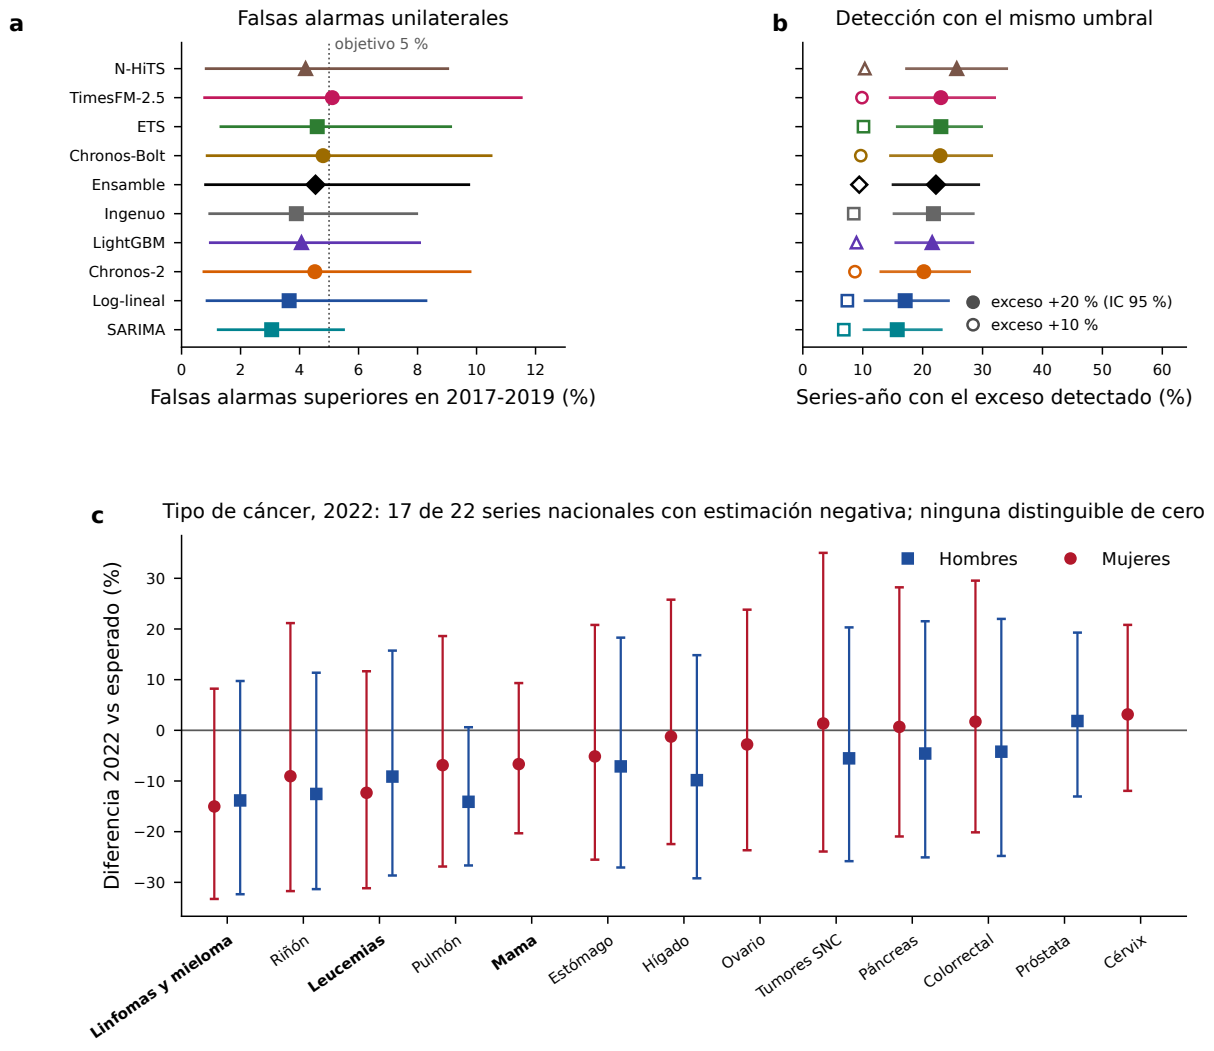

**Figura 3.** Falsas alarmas y detección de exceso en 2017-2019, años sin pandemia, con un umbral superior calibrado en años previos para cada año del plazo del pronóstico (objetivo común, 5 %). a: proporción de evaluaciones anuales de las series señaladas como exceso (IC 95 %). b: proporción en que se detectó un exceso simulado de 20 % (símbolos llenos, IC 95 %) o de 10 % (vacíos). c: diferencia entre mortalidad observada y esperada en 2022 en las series nacionales de cáncer (combinación de seis modelos; barras: intervalo de predicción de 90 %). LightGBM y N-HiTS se entrenaron conjuntamente con las series del estudio; Chronos-2 se evaluó sin adaptación local.

In [10]:
inventario.append(mostrar_figura(REPO, SALIDA, '3'))

In [11]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S9', plegada=False))

Modelo,"Falsas alarmas superiores, D1 (%)",Por año de prueba 2017 / 2018 / 2019 (%),Umbral superior mediano (%),"Detección +10 %, D1 (%)","Detección +20 %, D1 (%)",Δ detección +20 % vs log-lineal (pp),Bilateral 90 % (D3): superior / inferior (%)
LightGBM,4.1 (1.0-8.1),3.7 / 4.7 / 3.8,38,9.0 (4.3-14.7),21.6 (15.5-28.4),+4.5 (0.8 a 8.8),6.1 / 4.6
Ensamble,4.5 (0.8-9.7),3.6 / 5.3 / 4.7,49,9.4 (4.4-15.7),22.2 (15.1-29.4),+5.1 (1.8 a 9.0),7.2 / 1.5
TimesFM-2.5,5.1 (0.8-11.5),4.4 / 5.8 / 5.2,51,9.9 (3.8-17.6),23.0 (14.6-32.0),+6.0 (1.4 a 11.7),8.7 / 1.4
Chronos-2,4.5 (0.8-9.8),3.4 / 5.5 / 4.6,49,8.7 (3.5-15.6),20.2 (13.0-27.8),+3.1 (−0.9 a 7.6),7.5 / 1.7
Chronos-Bolt,4.8 (0.9-10.5),4.4 / 5.3 / 4.7,47,9.7 (3.8-17.0),22.9 (14.6-31.5),+5.8 (0.6 a 11.7),7.6 / 2.1
N-HiTS,4.2 (0.8-9.0),3.5 / 5.2 / 3.9,39,10.3 (5.1-16.4),25.7 (17.3-34.0),+8.6 (3.9 a 13.7),5.4 / 4.0
Log-lineal,3.6 (0.9-8.3),3.6 / 3.8 / 3.6,56,7.4 (3.1-12.8),17.1 (10.4-24.3),referencia,4.5 / 2.1
ETS amortiguado,4.6 (1.3-9.1),3.8 / 5.2 / 4.8,57,10.1 (5.4-15.7),23.0 (15.8-29.8),+6.0 (2.7 a 9.5),6.9 / 1.7
SARIMA,3.1 (1.2-5.5),2.7 / 3.2 / 3.2,59,6.8 (3.8-10.3),15.8 (10.2-23.1),−1.3 (−3.8 a 0.8),3.4 / 1.3
Ingenuo estacional,3.9 (1.0-8.0),3.5 / 4.6 / 3.6,50,8.5 (4.1-13.8),21.8 (15.2-28.4),+4.7 (0.8 a 9.1),6.4 / 2.1


In [12]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S10', plegada=True))

Modelo,Principal (por serie),Grupo de causa,Causa × sexo,Sin anidamiento,Nacionales,Nacionales × edad,Estatales,Estatales × edad
N,2870,28,52,1063,52,149,1127,1542
DC,0.25,2.56,1.88,0.42,1.88,1.11,0.4,0.34
LightGBM,3.21,1.93,2.03,3.08,5.63,4.46,3.14,3.07
Ensamble,3.52,3.25,3.22,3.61,2.62,3.1,3.58,3.54
TimesFM-2.5,4.01,3.18,3.12,3.87,4.85,4.29,3.93,4.02
Chronos-2,4.42,4.12,4.15,4.35,4.46,4.31,4.39,4.44
Chronos-Bolt,4.29,3.34,3.42,4.07,5.81,5.04,4.24,4.21
N-HiTS,5.17,5.64,5.57,5.2,5.52,5.29,5.22,5.11
Log-lineal,6.61,7.46,7.42,6.84,5.23,5.76,6.65,6.71
ETS amortiguado,6.77,7.29,7.26,6.77,5.83,6.48,6.8,6.81


In [13]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S10B', plegada=True))

a,b,dif,lo,hi
LightGBM global,Ensamble (mediana),-0.303833,-0.90384,0.288711
Ensamble (mediana),TimesFM-2.5,-0.496864,-1.05524,0.114395
TimesFM-2.5,Chronos-2,-0.401394,-0.756731,-0.0117308
Chronos-2,Chronos-Bolt,0.125436,-0.185416,0.436157
Chronos-2,N-HiTS global,-0.755749,-1.11875,-0.428801
N-HiTS global,Log-lineal,-1.43937,-2.13895,-0.823324
Log-lineal,ETS amortiguado,-0.159582,-0.815174,0.474724


En el panel 3c, la posición de cada cáncer combina datos del conjunto de series y sus intervalos. Una diferencia agregada entre cánceres no convierte cada diferencia individual en un resultado distinguible de cero. Los resultados completos del detector, sus controles y variantes aparecen en el suplemento del notebook.

<a id="mama"></a>
## 4. Aplicación al cáncer de mama

El ensamble y la regresión log-lineal se aplican a C50 en mujeres ≥ 20 años. La diferencia porcentual se calcula como **100 × (observado / esperado − 1)**. Un intervalo que incluye cero expresa compatibilidad con la referencia previa bajo los supuestos usados.

Los intervalos anuales nominales de 90 % transfieren errores de conteos de series de volumen similar a la TEE. Esa transferencia no está validada como garantía de cobertura de tasas. En 2024 no se validó el quinto año: se conserva la estimación puntual y se aplica la corrección de registro tardío correspondiente a cada indicador.

In [14]:
intervalos = pd.read_csv(B / "resultados/p1_intervalos_mama_entre_series.csv")
nacional = intervalos[(intervalos.target == "asmr") & (intervalos.year <= 2023)].copy()
nacional["Diferencia recalculada, %"] = 100 * (nacional.observado / nacional.esperado - 1)
# Observado y esperado están escritos con cuatro decimales; verificar a la precisión publicada.
np.testing.assert_allclose(nacional["Diferencia recalculada, %"], nacional.pscore, rtol=0, atol=0.0002)
display(nacional[["year", "Diferencia recalculada, %", "lo_todas", "hi_todas"]].rename(columns={
    "year":"Año", "lo_todas":"IP 90 % inferior", "hi_todas":"IP 90 % superior"}))

,Año,"Diferencia recalculada, %",IP 90 % inferior,IP 90 % superior
0,2020,1.201531,-7.5190,10.7444
1,2021,-2.178227,-14.1628,11.4797
2,2022,-6.280072,-19.9755,9.7592
3,2023,-7.811594,-24.9194,13.1944


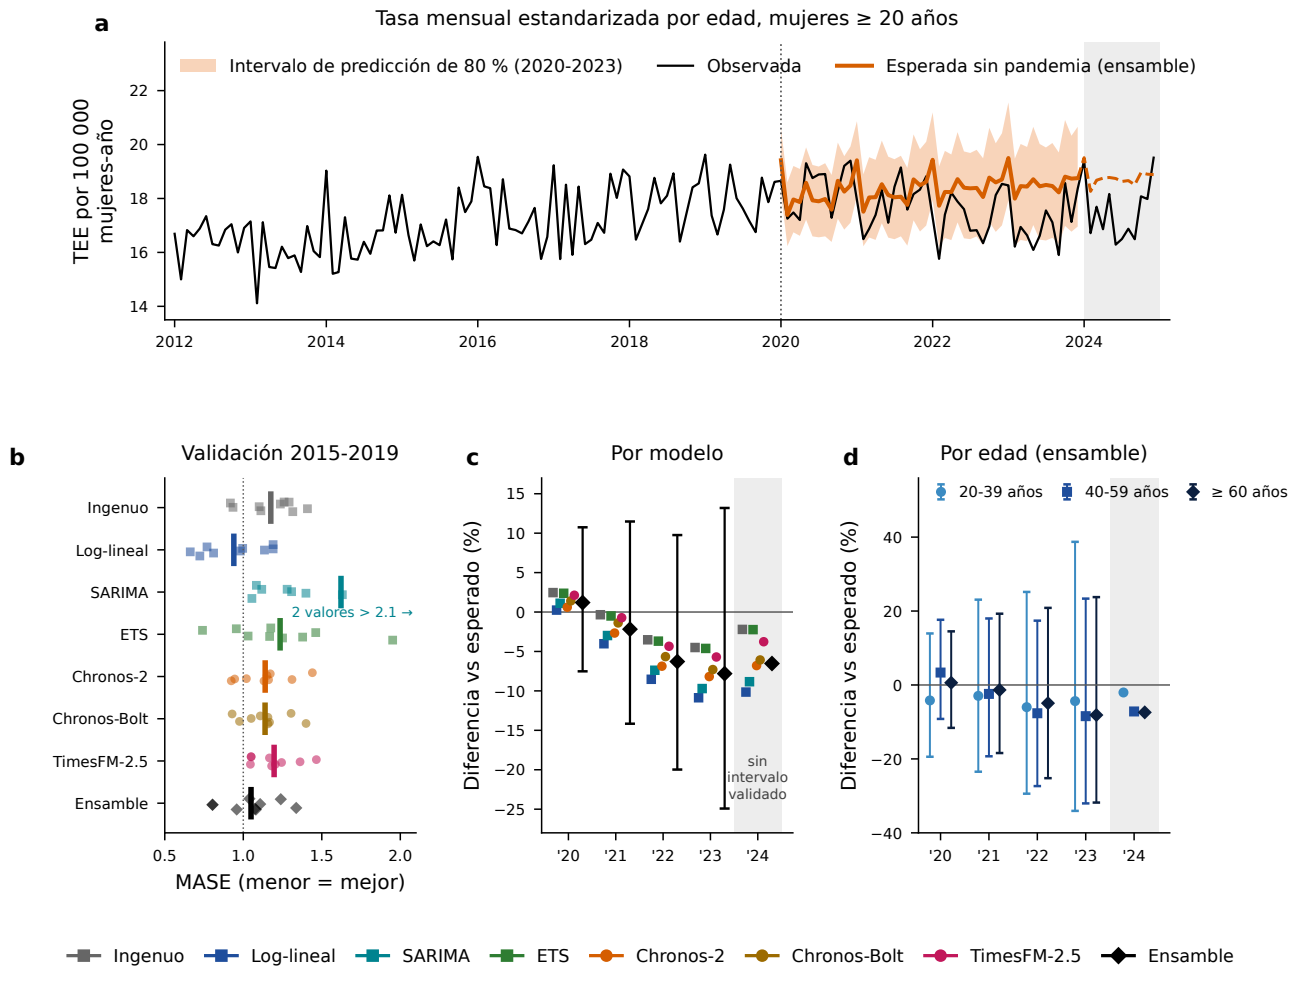

**Figura 4.** Cáncer de mama en mujeres de 20 años o más, 2012-2024. a: tasa estandarizada por edad (TEE) mensual, anualizada por 100 000 mujeres-año, observada y esperada sin pandemia (combinación de seis modelos; banda: intervalo de predicción mensual de 80 %, 2020-2023; discontinua: 2024, solo estimación puntual). b: error de validación en la serie nacional en nueve fechas de inicio trimestrales (puntos) y su media (barra). MASE: error absoluto medio del pronóstico dividido entre el del pronóstico ingenuo estacional dentro del periodo de entrenamiento; < 1 indica menor error que ese ingenuo, no una comparación con el ingenuo en el periodo de prueba. c: diferencia anual entre TEE observada y esperada por modelo; combinación con intervalo de predicción de 90 % de nivel nominal. d: diferencia por edad (combinación). Sombreado: 2024, sin validación del quinto año y con registro tardío corregido.

In [15]:
inventario.append(mostrar_figura(REPO, SALIDA, '4'))

In [16]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, '2', plegada=False))

Serie,2020,2021,2022,2023,2024†
"A. Nacional, mujeres ≥ 20 años",,,,,
TEE observada (por 100 000 mujeres-año),18.4,17.9,17.3,17.1,17.5
TEE esperada sin pandemia,18.2,18.3,18.5,18.6,18.8
"Diferencia, % (IP 90 %)",+1.2 (−7.5 a 10.7),−2.2 (−14.2 a 11.5),−6.3 (−20.0 a 9.8),−7.8 (−24.9 a 13.2),−6.5
Defunciones observadas,7 886,7 845,7 790,7 935,8 370
Defunciones esperadas sin pandemia,7 798,8 054,8 351,8 618,8 902
"Diferencia, % (IP 90 %)",+1.1 (−7.6 a 10.7),−2.6 (−14.5 a 11.0),−6.7 (−20.3 a 9.2),−7.9 (−25.0 a 13.1),−6.0
"TEE, modelo log-lineal (sensibilidad), % (IP 90 %)",+0.2 (−8.1 a 9.3),−4.0 (−16.3 a 10.0),−8.5 (−23.0 a 8.7),−10.9 (−27.5 a 9.6),−10.2
"B. Diferencia por subgrupo (TEE), % (IP 90 %)",,,,,
20-39 años,−4.2 (−19.4 a 13.9),−2.9 (−23.5 a 23.1),−6.0 (−29.4 a 25.2),−4.4 (−34.1 a 38.7),−2.0


In [17]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2H', plegada=True))

Modelo,MASE medio,MASE mediano,Mínimo-máximo,Cobertura observada del IP 80 % (%),Orígenes con MASE menor que el log-lineal (de 9)
Log-lineal,0.94,0.982,0.66-1.19,80.2,—
Ensamble,1.049,1.074,0.80-1.34,79.9,1
Chronos-Bolt,1.139,1.157,0.93-1.40,85.8,1
Chronos-2,1.139,1.151,0.92-1.44,82.7,1
Ingenuo estacional,1.175,1.236,0.92-1.41,76.2,0
TimesFM-2.5,1.196,1.18,1.05-1.47,67.9,1
ETS amortiguado,1.234,1.175,0.74-1.95,58.3,2
SARIMA,1.622,1.308,1.05-3.39,80.6,2


**Lectura.** En 2022 y 2023 las diferencias de TEE son aproximadamente −6.3 % y −7.8 %; sus intervalos incluyen cero. En la validación específica de mama, la comparación de MASE es diferente de la clasificación general de los 2 870 conteos. Los pronósticos y backtests originales de la aplicación (`tsfm_*`) son insumos guardados; aquí se recalculan sus resúmenes e intervalos disponibles.

### Reconstruir una tasa estandarizada

Para cada mes se divide el conteo de cada quinquenio por la población femenina correspondiente, se anualiza multiplicando por 12 y se pondera con la población estándar de la OMS. WPP se interpola al día 15 de cada mes. La tasa anual es el **promedio de las tasas mensuales anualizadas**. En esta comprobación usamos 2012–2023, sin aplicar a la tasa observada la corrección específica de 2024.

In [18]:
raw = pd.read_csv(DATOS / "c50/paquete_original/editorial/datos/c50_raw_2012_2024.csv.gz", dtype=str)
raw = raw.apply(lambda col: col.str.strip())
for col in ["sexo", "edad", "mes_ocurr", "anio_ocur", "anio_regis", "ent_resid", "tloc_resid", "sitio_ocur"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
c50 = raw[(raw.sexo == 2) & raw.edad.between(4020, 4997)
          & raw.mes_ocurr.between(1, 12) & raw.anio_ocur.between(2012, 2024)].copy()
c50["edad_anios"] = c50.edad - 4000
c50["fecha"] = pd.to_datetime(dict(year=c50.anio_ocur, month=c50.mes_ocurr, day=1))
c50["quinquenio"] = np.minimum(c50.edad_anios // 5 * 5, 85).astype(int)
meses = pd.date_range("2012-01-01", "2024-12-01", freq="MS")
pesos = pd.Series({20:8220, 25:7930, 30:7610, 35:7150, 40:6590, 45:6040, 50:5370,
                   55:4550, 60:3720, 65:2960, 70:2210, 75:1520, 80:910, 85:635}, dtype=float)
pesos /= pesos.sum()
wpp = pd.read_csv(DATOS / "c50/paquete_original/editorial/datos/wpp_mex_female_age5.csv")
wpp["quinquenio"] = np.minimum(wpp.AgeGrpStart, 85)
poblacion = wpp[wpp.quinquenio >= 20].groupby(["Time", "quinquenio"]).PopFemale.sum().unstack() * 1000
poblacion.index = pd.to_datetime(poblacion.index.astype(str) + "-07-01")
dia15 = meses + pd.Timedelta(days=14)
poblacion = poblacion.reindex(poblacion.index.union(dia15)).interpolate("time").loc[dia15]
poblacion.index = meses
conteos = c50.groupby(["fecha", "quinquenio"]).size().unstack(fill_value=0).reindex(index=meses, columns=pesos.index, fill_value=0)
tee = (conteos.div(poblacion[pesos.index]) * 12 * 100_000 * pesos).sum(axis=1)
series_originales = pd.read_csv(DATOS / "benchmark/datos/series_mensuales_C50.csv", parse_dates=["fecha"]).set_index("fecha")
np.testing.assert_allclose(tee.loc["2012":"2023"], series_originales.loc["2012":"2023", "asmr"], rtol=1e-9, atol=1e-12)
display(tee.loc["2020":"2023"].groupby(lambda fecha: fecha.year).mean().rename("TEE anual observada").to_frame().round(1))

,TEE anual observada
2020,18.4
2021,17.9
2022,17.3
2023,17.1


<a id="exploratorios"></a>
## 5. Tendencia y lugar de defunción

La tendencia ajusta el logaritmo de la TEE mensual con tiempo, un cambio de nivel desde marzo de 2020, un cambio de pendiente e indicadores de mes. La pendiente posterior combina los coeficientes de tiempo y cambio de pendiente. La covarianza temporal robusta se conserva en los scripts originales.

Para lugar de defunción, los modelos logísticos ajustan edad, entidad y mes. Sus probabilidades estandarizadas se comparan con la continuación descriptiva de la tendencia previa. Las bandas son **IC de parámetros o medias ajustadas**, distintos de los intervalos predictivos de la aplicación principal.

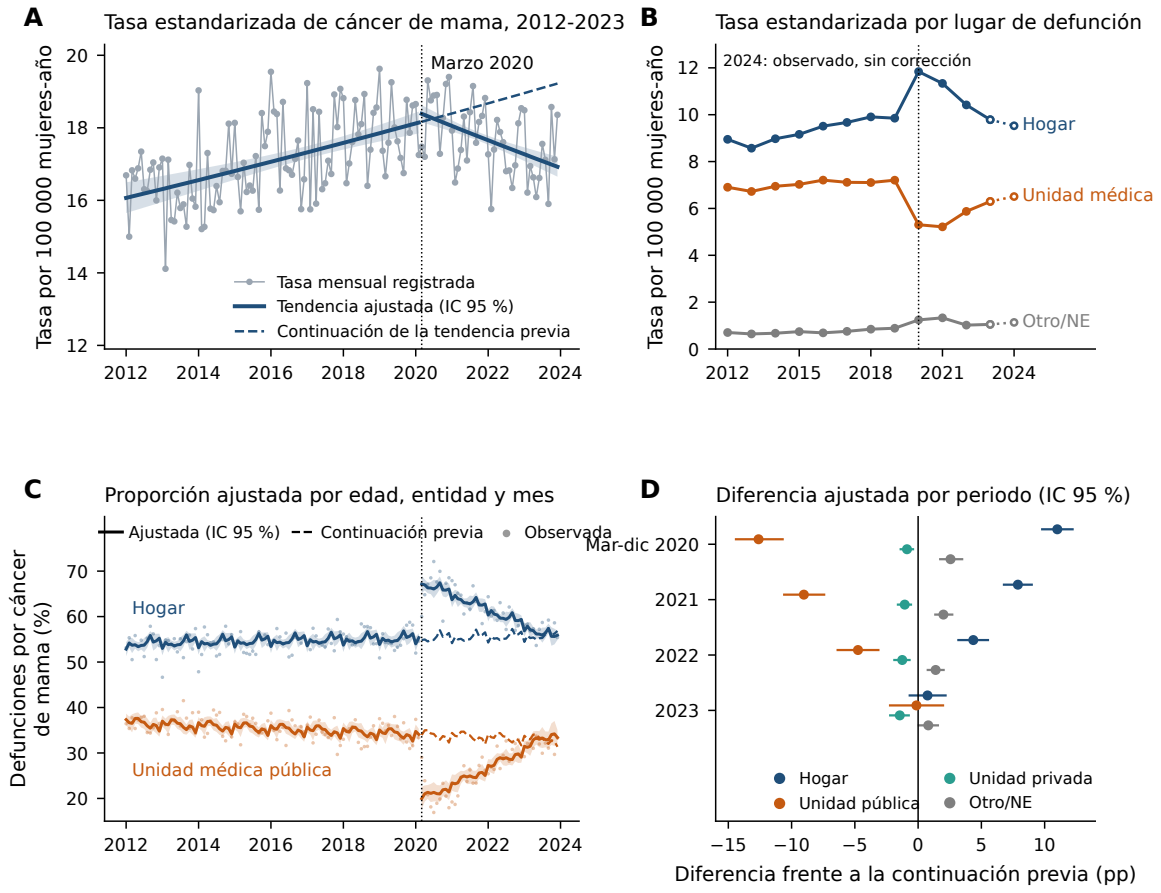

**Figura 5.** Análisis exploratorios de cáncer de mama en mujeres de 20 años o más. a: tasa estandarizada por edad (TEE), tendencia segmentada y continuación de la tendencia previa a marzo de 2020 (discontinua); banda: IC 95 % de la tendencia. b: media anual de las tasas mensuales por lugar; unidades médicas: públicas y privadas; 2024 (símbolo vacío), observado sin corrección. c: proporciones ajustadas por edad, entidad y mes (bandas: IC 95 %), continuación previa y valores observados (puntos). d: diferencias ajustadas frente a la continuación previa, en puntos porcentuales; IC 95 % por 10 000 simulaciones. Ajustes: 2012-2023; covarianza temporal robusta con 12 rezagos. Las líneas discontinuas son continuaciones descriptivas de modelos ajustados a toda la serie. Los IC no son intervalos de predicción; las diferencias no identifican causas.

In [19]:
inventario.append(mostrar_figura(REPO, SALIDA, '5'))

In [20]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S19', plegada=True))

parametro,Análisis,Serie,"Cambio de pendiente, %","Pendiente posterior, %/año","Pendiente previa, %/año","Cambio de nivel, %"
,2023 + registro tardío (media),Nacional,-3.57 (-4.38 a -2.75),-2.11 (-2.80 a -1.41),1.52 (1.04 a 1.99),1.13 (-1.03 a 3.33)
,2023 + registro tardío (máximo),Nacional,-3.55 (-4.37 a -2.72),-2.09 (-2.78 a -1.39),1.52 (1.04 a 1.99),1.11 (-1.06 a 3.32)
,HAC6,Nacional,-3.64 (-4.69 a -2.58),-2.18 (-3.13 a -1.22),1.52 (1.06 a 1.98),1.21 (-1.53 a 4.02)
,cuasi-Poisson por edad,Nacional,-3.64 (-4.36 a -2.91),-2.21 (-2.83 a -1.58),1.49 (1.06 a 1.92),1.24 (-0.79 a 3.31)
,"edad, modelo conjunto DK",20-39,-0.92 (-2.59 a 0.78),0.21 (-1.14 a 1.58),1.14 (0.05 a 2.24),-4.31 (-8.24 a -0.21)
,"edad, modelo conjunto DK",40-59,-4.57 (-5.84 a -3.28),-3.62 (-4.71 a -2.52),0.99 (0.29 a 1.70),2.41 (-1.41 a 6.39)
,"edad, modelo conjunto DK",60+,-3.26 (-4.51 a -2.00),-1.26 (-2.40 a -0.10),2.07 (1.65 a 2.49),0.79 (-1.74 a 3.40)
,edad_exploratorio,asmr_20-39,-0.92 (-2.68 a 0.87),0.21 (-1.21 a 1.65),1.14 (-0.01 a 2.30),-4.31 (-8.44 a 0.02)
,edad_exploratorio,asmr_40-59,-4.57 (-5.91 a -3.21),-3.62 (-4.77 a -2.47),0.99 (0.25 a 1.73),2.41 (-1.61 a 6.60)
,edad_exploratorio,asmr_60+,-3.26 (-4.57 a -1.94),-1.26 (-2.46 a -0.04),2.07 (1.63 a 2.51),0.79 (-1.88 a 3.54)


In [21]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S20', plegada=True))

parametro,Desenlace,Análisis,"Cambio de nivel, RM","Cambio de pendiente, RM/año","Pendiente previa, RM/año",Eventos / defunciones,"Wald nivel y pendiente, p"
,Hogar,principal,1.727 (1.623 a 1.838),0.855 (0.836 a 0.875),1.006 (0.999 a 1.013),47310 / 82859,1.39e-68
,Hogar,sens_2024_ponderado_completitud,1.690 (1.580 a 1.808),0.868 (0.850 a 0.887),1.006 (0.999 a 1.013),51948 / 91221,3.58e-58
,Hogar,sens_2024_sin_ponderar,1.688 (1.577 a 1.807),0.869 (0.850 a 0.888),1.006 (0.999 a 1.013),51856 / 91037,1.09e-55
,Hogar,sens_HAC6,1.727 (1.600 a 1.865),0.855 (0.834 a 0.877),1.006 (0.999 a 1.014),47310 / 82859,3.99e-47
,Hogar,sens_abril2020,1.739 (1.643 a 1.841),0.844 (0.825 a 0.863),1.008 (1.001 a 1.015),47310 / 82859,3.65e-88
,Hogar,sens_lugar_conocido,1.789 (1.672 a 1.915),0.847 (0.826 a 0.868),1.004 (0.997 a 1.011),47310 / 81981,6.72e-64
,Hogar,sens_no_residentes,1.722 (1.619 a 1.832),0.855 (0.836 a 0.875),1.007 (1.000 a 1.014),47378 / 83174,2.96e-68
,Hogar,sens_region,1.716 (1.610 a 1.829),0.855 (0.836 a 0.875),1.007 (1.000 a 1.014),47310 / 82859,2.03e-64
,Otro/NE,principal,1.654 (1.387 a 1.971),0.900 (0.846 a 0.958),1.023 (1.005 a 1.042),4284 / 82859,1.37e-07
,Unidad privada,principal,0.857 (0.767 a 0.958),0.963 (0.925 a 1.002),1.017 (1.002 a 1.032),4502 / 82859,0.000637


In [22]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S21A', plegada=True))

Desenlace,Periodo,"Ajustada, % (IC 95 %)","Continuación previa, % (IC 95 %)","Diferencia principal, pp (IC 95 %)","Diferencia indicadores posteriores, pp (IC 95 %)"
Hogar,2019,55.2 (54.4 a 55.9),55.2 (54.4 a 55.9),0.0 (0.0 a 0.0),0.0 (0.0 a 0.0)
Hogar,mar-dic 2020,66.4 (65.4 a 67.4),55.4 (54.5 a 56.4),11.0 (9.7 a 12.3),11.3 (9.9 a 12.6)
Hogar,2021,63.3 (62.7 a 64.0),55.5 (54.4 a 56.5),7.9 (6.7 a 9.1),7.7 (5.8 a 9.6)
Hogar,2022,60.0 (59.6 a 60.3),55.6 (54.4 a 56.8),4.4 (3.1 a 5.6),4.2 (2.6 a 5.8)
Hogar,2023,56.5 (56.0 a 57.0),55.7 (54.4 a 57.1),0.7 (-0.8 a 2.3),1.1 (-0.3 a 2.6)
Unidad pública,2019,34.2 (33.4 a 35.1),34.2 (33.4 a 35.1),0.0 (0.0 a 0.0),0.0 (0.0 a 0.0)
Unidad pública,mar-dic 2020,21.2 (19.7 a 22.9),33.8 (32.8 a 34.9),-12.6 (-14.5 a -10.6),-13.2 (-14.9 a -11.4)
Unidad pública,2021,24.6 (23.4 a 25.9),33.6 (32.4 a 34.9),-9.0 (-10.7 a -7.3),-9.1 (-11.4 a -6.8)
Unidad pública,2022,28.5 (27.6 a 29.5),33.3 (31.9 a 34.7),-4.8 (-6.4 a -3.1),-3.5 (-5.5 a -1.5)
Unidad pública,2023,32.8 (31.4 a 34.3),33.0 (31.4 a 34.6),-0.1 (-2.3 a 2.1),-1.1 (-2.7 a 0.5)


In [23]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S21B', plegada=True))

Desenlace,"Tendencia segmentada (pp, IC 95 %)","Indicadores anuales (pp, IC 95 %)","Indicadores de todos los años (pp, IC 95 %)"
Hogar,1.3 (0.4 a 2.3),1.7 (0.7 a 2.6),2.2 (0.7 a 3.6)
Unidad pública,-1.4 (-3.1 a 0.4),-2.3 (-3.3 a -1.3),-3.1 (-4.4 a -1.7)
Unidad privada,-1.1 (-1.6 a -0.5),-0.8 (-1.3 a -0.4),-0.3 (-0.6 a -0.01)
Otro/NE,1.2 (0.6 a 1.9),1.4 (1.0 a 1.8),1.2 (0.9 a 1.5)


**Lectura.** La pendiente de TEE disminuye después de marzo de 2020 en el ajuste principal; al excluir 2020, su incertidumbre permite una pendiente nula. El aumento de la proporción domiciliaria en 2020 no permite atribuir causas ni medir por sí mismo acceso o calidad de atención. Las continuaciones previas se derivan de modelos ajustados a toda la serie.

<a id="apvp"></a>
## 6. Mortalidad prematura y tamaño de localidad

Los APVP asignan a cada muerte a los 20–74 años **75 − edad cumplida − 0.5** años. Desde los 75 años la contribución es cero. Se mantienen todas las residencias para el indicador nacional.

El cálculo visible de 2023 se realiza directamente desde los registros filtrados y se coteja con la salida de C50. Para APVP de 2024 se conserva en el análisis completo la corrección por registro tardío, descrita en las notas de las tablas.

In [24]:
c50["apvp"] = np.maximum(75 - c50.edad_anios - 0.5, 0)
registros_2023 = c50[c50.anio_ocur == 2023]
apvp_2023 = registros_2023.apvp.sum()
apvp_anuales = pd.read_csv(C / "resultados/v12_apvp_localidad/APVP_anual.csv").set_index("anio")
np.testing.assert_allclose(apvp_2023, apvp_anuales.loc[2023, "APVP_total"], rtol=0, atol=1e-9)
aporte_40_59 = 100 * registros_2023.loc[registros_2023.edad_anios.between(40, 59), "apvp"].sum() / apvp_2023
assert apvp_2023 == 120893 and round(aporte_40_59, 1) == 65.2
print(f"2023: {apvp_2023:,.0f} APVP; {aporte_40_59:.1f} % en mujeres de 40–59 años.")

2023: 120,893 APVP; 65.2 % en mujeres de 40–59 años.


In [25]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S25A', plegada=False))

anio,APVP_total,APVP_tasa_estandarizada
2012,94633,277.8
2013,91743.5,261.7
2014,100056,276.8
2015,101994,275.9
2016,107788,284.4
2017,112692,289.7
2018,116088,291.5
2019,118591,291
2020,123822,297.4
2021,120832,284.7


In [26]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S25B', plegada=True))

Variante,Parámetro,Cambio % (IC 95 %),p
principal_2012_2023,Pendiente previa,1.15 (0.55 a 1.76),< 0.001
principal_2012_2023,Pendiente posterior,-2.55 (-3.55 a -1.53),< 0.001
principal_2012_2023,Cambio de nivel,0.37 (-3.18 a 4.04),0.842
principal_2012_2023,Cambio de pendiente,-3.66 (-4.75 a -2.55),< 0.001
sin_2020_2012_2023,Pendiente previa,1.18 (0.55 a 1.81),< 0.001
sin_2020_2012_2023,Pendiente posterior,-1.07 (-2.67 a 0.55),0.196
sin_2020_2012_2023,Cambio de nivel,-3.69 (-8.58 a 1.48),0.159
sin_2020_2012_2023,Cambio de pendiente,-2.22 (-3.89 a -0.52),0.011
con_2024_corregido,Pendiente previa,1.15 (0.55 a 1.76),< 0.001
con_2024_corregido,Pendiente posterior,-1.53 (-2.63 a -0.41),0.007


Para comparar localidades se restringe a residentes en México con ocurrencia en 2012–2023. Los códigos de tamaño de localidad se agrupan según el suplemento. El denominador incluye **todas las defunciones del grupo**, incluso sitio no especificado (99); la sensibilidad excluye únicamente ese código. Son proporciones entre fallecidas, no tasas de mortalidad poblacionales.

In [27]:
residentes = c50[c50.ent_resid.between(1, 32) & (c50.anio_ocur <= 2023)].copy()
residentes["localidad"] = pd.cut(residentes.tloc_resid, [0, 3, 6, 12, 17],
    labels=["< 2 500", "2 500-14 999", "15 000-99 999", "≥ 100 000"])
local_2023 = residentes[residentes.anio_ocur == 2023].groupby("localidad", observed=True).agg(
    total=("sitio_ocur", "size"), hogar=("sitio_ocur", lambda x: (x == 11).sum()),
    sitio99=("sitio_ocur", lambda x: (x == 99).sum()))
local_2023["Hogar %"] = 100 * local_2023.hogar / local_2023.total
local_2023["Hogar % sin 99"] = 100 * local_2023.hogar / (local_2023.total - local_2023.sitio99)
local_salida = pd.read_csv(C / "resultados/v12_apvp_localidad/localidad_hogar.csv").query("anio == 2023").set_index("localidad")
np.testing.assert_allclose(local_2023["Hogar %"], local_salida.loc[local_2023.index, "hogar_pct"], rtol=1e-9, atol=1e-12)
assert round(local_2023.loc["< 2 500", "Hogar %"], 1) == 70.2
assert round(local_2023.loc["≥ 100 000", "Hogar %"], 1) == 53.0
display(local_2023.round(1))

,total,hogar,sitio99,Hogar %,Hogar % sin 99
localidad,,,,,
< 2 500,851,597,4,70.2,70.5
2 500-14 999,892,565,5,63.3,63.7
15 000-99 999,1311,785,7,59.9,60.2
≥ 100 000,4857,2576,35,53.0,53.4


In [28]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S25C', plegada=False))

Habitantes,Año,Hogar / total,Hogar %,Sitio 99 n,Hogar % sin 99
< 2 500,2019,607/897,67.7,11,68.5
< 2 500,2020,711/942,75.5,14,76.6
< 2 500,2023,597/851,70.2,4,70.5
2 500-14 999,2019,542/819,66.2,7,66.7
2 500-14 999,2020,627/911,68.8,12,69.7
2 500-14 999,2023,565/892,63.3,5,63.7
15 000-99 999,2019,665/1234,53.9,15,54.6
15 000-99 999,2020,871/1307,66.6,22,67.8
15 000-99 999,2023,785/1311,59.9,7,60.2
≥ 100 000,2019,2238/4437,50.4,31,50.8


**Lectura.** El total de APVP puede aumentar mientras su tasa estandarizada disminuye. De igual manera, una proporción mayor de muertes en el hogar describe la distribución del lugar entre fallecidas; no demuestra mayor mortalidad de la población rural ni identifica preferencias o cuidados paliativos.

<a id="suplemento"></a>
## 7. Análisis complementarios y material suplementario

Este apartado completa la presentación de los análisis disponibles. Las tablas ya presentadas conservan su único punto de lectura en las secciones anteriores. Las restantes se agrupan por pregunta científica y mantienen la **numeración de la base histórica**, sin incorporar el análisis ajustado de localidad de otras versiones editoriales.

### Ajuste fino de Chronos-2

La figura 6 y la tabla S4 resumen resultados guardados de adaptación LoRA y ajuste completo. Se recalcula la agregación disponible, sin volver a entrenar. Las barras principales corresponden a semilla 0; los tres puntos LoRA muestran semillas 0, 1 y 2. El piloto de la figura S3 es histórico y diferente de este análisis.

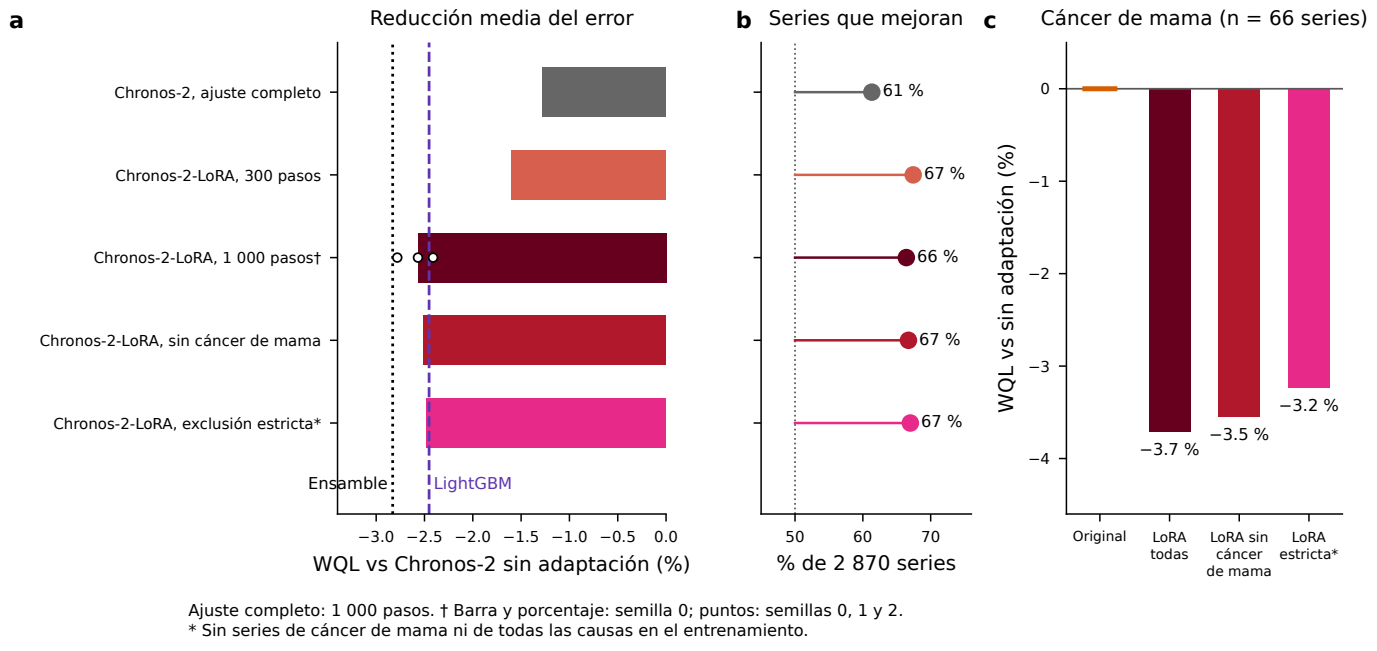

**Figura 6.** Ajuste fino de Chronos-2 (inicio en diciembre de 2016, 36 meses). Chronos-2-LoRA: adaptación mediante LoRA; ajuste completo: actualización de todos los parámetros. a: error (WQL) relativo a Chronos-2 sin adaptación (media geométrica por serie); barras con semilla 0 y puntos con semillas 0, 1 y 2 para LoRA de 1 000 pasos. b: proporción de series que mejoran con semilla 0. c: Chronos-2 sin adaptación y LoRA con todas las series, sin series de mama y con exclusión estricta (sin mama ni todas las causas). LightGBM se entrenó con datos del estudio; las líneas de referencia corresponden al mismo origen y horizonte.

In [29]:
inventario.append(mostrar_figura(REPO, SALIDA, '6'))

In [30]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S4', plegada=True))

variante,todas_n,todas_WQL_rel_geo,todas_mejora_media_pct,todas_pct_series_mejoran,todas_wilcoxon_p,mama_n,mama_WQL_rel_geo,mama_mejora_media_pct,mama_pct_series_mejoran,mama_wilcoxon_p,todascausas_n,todascausas_WQL_rel_geo,todascausas_mejora_media_pct,todascausas_pct_series_mejoran,todascausas_wilcoxon_p,resto_n,resto_WQL_rel_geo,resto_mejora_media_pct,resto_pct_series_mejoran,resto_wilcoxon_p,WQL_rel_media_aritm_de_razones,cob80
LoRA 1000 s0,2870,0.974326,2.56736,66.4111,4.70774e-77,66,0.962873,3.71275,80.303,1.72555e-08,264,0.957075,4.29254,68.5606,1.03918e-12,2540,0.976437,2.35627,65.8268,1.58113e-61,0.977062,79.2828
LoRA 1000 s1,2870,0.975887,2.4113,67.0732,1.04874e-79,66,0.965103,3.48974,84.8485,6.49169e-09,264,0.960877,3.91229,68.1818,4.92273e-12,2540,0.977743,2.22573,66.4961,2.68866e-64,0.97861,79.5383
LoRA 1000 s2,2870,0.972183,2.78167,67.77,1.51332e-94,66,0.963823,3.61768,81.8182,3.10745e-08,264,0.951332,4.86682,75,4.02835e-17,2540,0.974595,2.54047,66.6535,2.79602e-74,0.974966,79.6651
LoRA 300 s0,2870,0.984026,1.59737,67.4216,7.67525e-84,66,0.982794,1.72065,77.2727,5.16686e-06,264,0.970973,2.90271,71.5909,9.01549e-14,2540,0.985425,1.45748,66.7323,3.47751e-68,0.98535,80.6552
LoRA 1000 sin mama,2870,0.97491,2.50902,66.7247,4.47138e-76,66,0.964543,3.54571,81.8182,2.15401e-08,264,0.957966,4.20341,69.697,3.22901e-12,2540,0.976959,2.30407,66.0236,4.73772e-61,0.977609,79.3748
Completo 1000 s0,2870,0.98725,1.27505,61.324,7.43283e-27,66,0.952477,4.75231,86.3636,9.95065e-10,264,0.99656,0.343958,56.8182,0.111915,2540,0.987206,1.27938,61.1417,9.71329e-24,0.991765,79.065
LoRA 1000 estricto (sin C50 ni todas las causas),2870,0.975198,2.48016,67.0035,1.57652e-82,66,0.967677,3.23226,81.8182,4.97428e-08,264,0.96368,3.63198,68.9394,3.70383e-11,2540,0.9766,2.34001,66.4173,3.13783e-68,0.97764,79.397


### Composición del corpus y validación a cuatro años

S1 reconstruye los conteos de series; los códigos CIE-10 y tipos se conservan como definiciones editoriales. S2A se reconstruye desde los NPZ de 48 meses mediante el script independiente incluido en el repositorio.

In [31]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S1', plegada=True))

Tipo,Grupo,CIE10,Nacional,Nacional×edad,Estatal,Estatal×edad,Total series
Cánceres,C. mama,C50,1,3,27,35,66
Cánceres,C. cérvix,C53,1,3,22,22,48
Cánceres,C. ovario,C56,1,3,15,11,30
Cánceres,C. próstata,C61,1,2,27,29,59
Cánceres,C. pulmón,C33-C34,2,6,36,34,78
Cánceres,C. colorrectal,C18-C21,2,6,34,27,69
Cánceres,C. estómago,C16,2,6,37,29,74
Cánceres,C. hígado,C22,2,6,40,35,83
Cánceres,C. páncreas,C25,2,4,27,17,50
Cánceres,Leucemias,C91-C95,2,6,26,15,49


In [32]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2A', plegada=True))

Modelo,año 1,año 2,año 3,año 4,0-48,cov_h1,cov_h2,cov_h3,cov_h4,rango_serie,FPR_año4,semiancho_año4
LightGBM global,-12.3,-14.7,-19.5,-24.8,-17.9,74.5,70.6,68.9,67,2.83,9.7,44.9
Ensamble (mediana),-10.3,-13.6,-16.7,-20,-15.8,81.3,81.9,82.4,82.6,3.47,9.6,52.5
TimesFM-2.5,-10,-12.3,-15.6,-18.3,-14.3,80.5,79.4,77.8,75.6,3.91,9.5,57.9
Chronos-Bolt,-7.2,-12.1,-14.2,-17.2,-13.5,84.2,85.1,85.3,84.1,4.03,9.8,54.3
Chronos-2,-8,-12.5,-14.2,-16.8,-13.6,84.3,85.7,86.3,86.5,4.29,10,54.6
Log-lineal,0,0,0,0,0,77.6,74.7,73.1,71.8,6.51,6.1,101.4
ETS amortiguado,0.9,-0.3,-3.6,-7.1,-2.1,61.5,59.2,58.1,56.4,6.57,9,64.2
N-HiTS global,-7.3,-11.6,-7.7,23.3,1.8,80.8,80.2,71.5,39.2,7.18,3.7,94.6
SARIMA,6.5,11.5,20.4,30.6,19.9,78.7,81.5,82.9,83.9,7.94,5.1,147
Ingenuo estacional,14.9,10.8,5.7,-0.2,7.1,75.1,70.7,67.8,65.6,8.27,10.3,51.4


In [33]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S15', plegada=True))

Modelo,Familia,Rango WQL,"Reducción de WQL vs log-lineal, % (IC 95 %)",Cobertura observada del IP 80 % (%),"Falsas alarmas, IP bilateral 90 % (%)",Semiancho IP 90 % (%),"Falsas alarmas superiores, unilateral (%)","Detección de +20 %, unilateral (%)"
LightGBM,Global (IA),3.21,13.3 (10.6 a 16.2),72.1,10.1,30,4.1,21.6
Ensamble,Ensamble (clásicos + fundacionales),3.52,12.4 (9.9 a 14.8),82,8.6,34,4.5,22.2
TimesFM-2.5,Fundacional (IA),4.01,10.9 (6.9 a 14.7),79.7,10,36,5.1,23
Chronos-Bolt,Fundacional (IA),4.29,9.8 (5.4 a 13.9),84.7,9.6,34,4.8,22.9
Chronos-2,Fundacional (IA),4.42,10.4 (7.0 a 13.6),84.8,9,35,4.5,20.2
N-HiTS,Global (IA),5.17,7.9 (4.6 a 11.4),78.6,9,31,4.2,25.7
Log-lineal,Clásico,6.61,referencia,75.5,6.4,45,3.6,17.1
ETS,Clásico,6.77,0.7 (−3.0 a 4.1),62.2,8.1,39,4.6,23
SARIMA,Clásico,7.99,−10.8 (−12.6 a −9.1),81.2,4.7,52,3.1,15.8
Ingenuo estacional,Clásico,9,−12.8 (−17.6 a −8.2),71.5,8.5,35,3.9,21.8


### Incertidumbre de la aplicación a mama

Las tablas S2B–S2G separan rangos por serie, calibración entre series, composición del conjunto y comprobaciones con separación temporal. No convierten el nivel nominal del IP en una cobertura demostrada para TEE. S3 presenta variantes desde un CSV guardado cuyo generador no fue localizado. S6 y S8 también dependen de etapas guardadas.

In [34]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2B', plegada=True))

Serie,Año,Diferencia (%),Rango por serie (descriptivo),IP 90 % entre series (todas),IP 90 % entre series (nacionales),Estrato de volumen
"Nacional, TEE",2020,+1.2,−5.4 a 8.3,−7.5 a 10.7,−9.0 a 12.5,300-1000
"Nacional, TEE",2021,−2.2,−7.5 a 3.4,−14.2 a 11.5,−15.5 a 13.3,300-1000
"Nacional, TEE",2022,−6.3,−13.5 a 1.5,−20.0 a 9.8,−26.0 a 18.8,300-1000
"Nacional, TEE",2023,−7.8,−14.7 a −0.4,−24.9 a 13.2,−31.1 a 23.3,300-1000
"Nacional, TEE",2024,−6.5,−13.7 a 1.2,(−23.9 a 14.8),(−30.1 a 25.0),300-1000
20-39 años (TEE),2020,−4.2,−19.1 a 13.4,−19.4 a 13.9,−16.3 a 9.7,25-100
20-39 años (TEE),2021,−2.9,−17.8 a 14.6,−23.5 a 23.1,−16.7 a 13.1,25-100
20-39 años (TEE),2022,−6.0,−18.5 a 8.4,−29.4 a 25.2,−20.5 a 11.1,25-100
20-39 años (TEE),2023,−4.4,−18.2 a 11.9,−34.1 a 38.7,−22.8 a 18.5,25-100
20-39 años (TEE),2024,−2.0,−15.1 a 13.0,(−32.5 a 42.1),(−20.9 a 21.3),25-100


In [35]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2C', plegada=True))

Año del horizonte,Errores de calibración (n),"Rango requerido, entero superior de (n + 1) × 0.9",Rango usado,"Nivel nominal del máximo, n/(n+1) (%)",Correlación entre orígenes consecutivos,Sesgo medio (%),Máximo |error| (log)
1,9,9,9,90,0.57,1.7,0.068
2,9,9,9,90,0.38,2.4,0.056
3,9,9,9,90,0.55,4.1,0.08
4,5,6,5,83.3,0.998,6.9,0.078


In [36]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2D', plegada=True))

variante,bloque,vol,n_cal,n_prueba,FPR,sesgo_prueba_pct
Mondrian volumen (todas las series),1,100-300,486,243,9.88,3.39
Mondrian volumen (todas las series),1,25-100,1370,685,8.61,3.11
Mondrian volumen (todas las series),1,300-1000,262,131,3.05,1.44
Mondrian volumen (todas las series),1,todos,5740,2870,8.26,4.69
Mondrian volumen (todas las series),2,100-300,486,243,4.94,2.56
Mondrian volumen (todas las series),2,25-100,1370,685,9.93,2.64
Mondrian volumen (todas las series),2,300-1000,262,131,4.58,1.8
Mondrian volumen (todas las series),2,todos,5740,2870,9.3,4.8
Mondrian volumen (todas las series),3,100-300,486,243,4.53,4.66
Mondrian volumen (todas las series),3,25-100,1370,685,8.47,4.07


In [37]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2E', plegada=True))

Año del horizonte,Estrato (defunciones/mes),Errores de calibración,De series C50 o «todas las causas»,% con C50 o todas las causas
1,100-300,786,258,32.8
1,25-100,2118,192,9.1
1,300-1000,420,270,64.3
2,100-300,786,258,32.8
2,25-100,2118,192,9.1
2,300-1000,420,270,64.3
3,100-300,786,258,32.8
3,25-100,2118,192,9.1
3,300-1000,420,270,64.3
4,100-300,524,172,32.8


In [38]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2F', plegada=True))

Año del horizonte,Serie de mama,Variable,Año de prueba,Años de calibración,Estrato,n,Umbral,Error,Fuera
1,"Nacional, TEE",tasa,2017,"2015, 2016",300-1000,96,0.119,+0.042,no
1,"Nacional, defunciones",conteo,2017,"2015, 2016",300-1000,96,0.119,+0.061,no
1,20-39 años (TEE),tasa,2017,"2015, 2016",25-100,1234,0.174,+0.082,no
1,40-59 años (TEE),tasa,2017,"2015, 2016",100-300,308,0.141,+0.040,no
1,≥ 60 años (TEE),tasa,2017,"2015, 2016",100-300,308,0.141,+0.019,no
2,"Nacional, TEE",tasa,2018,"2016, 2017",300-1000,96,0.147,+0.055,no
2,"Nacional, defunciones",conteo,2018,"2016, 2017",300-1000,96,0.147,+0.093,no
2,20-39 años (TEE),tasa,2018,"2016, 2017",25-100,1234,0.232,−0.008,no
2,40-59 años (TEE),tasa,2018,"2016, 2017",100-300,308,0.217,+0.061,no
2,≥ 60 años (TEE),tasa,2018,"2016, 2017",100-300,308,0.217,+0.035,no


In [39]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S2G', plegada=True))

target,year,pscore,lo_todas,hi_todas,lo_sin_C50_ni_todas,hi_sin_C50_ni_todas
asmr,2020,1.20157,-7.51899,10.7444,-9.68692,13.4028
asmr,2021,-2.17823,-14.1628,11.4797,-15.8303,13.6881
asmr,2022,-6.28007,-19.9755,9.7592,-24.473,16.2951
asmr,2023,-7.81157,-24.9194,13.1944,-29.1953,20.0303
deaths_adj,2020,1.12913,-7.5852,10.6652,-9.75157,13.3216
deaths_adj,2021,-2.59589,-14.5293,11.0037,-16.1897,13.2027
deaths_adj,2022,-6.71536,-20.3472,9.24941,-24.8237,15.755
deaths_adj,2023,-7.9219,-25.0092,13.0589,-29.2801,19.8866
asmr_20-39,2020,-4.18037,-19.4166,13.9367,-19.7154,14.3607
asmr_20-39,2021,-2.9439,-23.4645,23.0786,-23.9288,23.8299


In [40]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S3', plegada=True))

Unnamed: 0,Unnamed: 1,Chronos-2,Chronos-Bolt,ETS amortiguado,Ensamble (mediana),Ingenuo estacional,LightGBM global,Log-lineal,N-HiTS global,SARIMA,TimesFM-2.5
Mondrian volumen,FPR,9,9.6,8.1,8.6,8.5,10.1,6.4,9,4.7,10
Mondrian volumen,semiancho_mediana,34.6,33.9,38.8,34.1,35,30,45.2,30.9,51.9,36.1
Mondrian volumen,FPR_nacional,7.1,7.7,9.6,7.1,6.4,9,5.8,7.7,5.8,7.7
Mondrian volumen,semiancho_nacional,16,19.3,18.9,16.3,18.5,14.5,18,15.9,20.6,16.7
Mondrian volumen×nivel,FPR,8.8,9.3,8,8.4,8.3,9.6,6.1,8.8,4.5,9.8
Mondrian volumen×nivel,semiancho_mediana,35.6,34.5,40.1,34.9,35.3,31.2,48.5,32.1,57.2,36.8
Mondrian volumen×nivel,FPR_nacional,5.8,5.1,6.4,7.1,5.1,3.8,5.1,5.1,4.5,7.1
Mondrian volumen×nivel,semiancho_nacional,15.8,17.7,24.8,13.7,19.1,16.6,20.4,14.4,21.4,17.7
Normalizado por ruido,FPR,7.2,6.2,6.9,7,6.5,9.6,6.4,8.1,4.3,7.8
Normalizado por ruido,semiancho_mediana,37.8,41.3,41.3,36,39.2,31.3,43.3,34.6,50.6,39.4


In [41]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S6', plegada=True))

model,cob80_original,cob80_CQR,ancho_rel_original,ancho_rel_CQR,WQL_original,WQL_CQR,WQL_CQR_rel_loglin
Chronos-2,83.643,77.485,79.487,67.78,0.151,0.151,0.898
Chronos-Bolt,84.384,79.065,81.916,70.658,0.152,0.152,0.9
TimesFM-2.5,80.677,81.246,75.137,74.924,0.151,0.151,0.899
Ingenuo estacional,72.02,80.714,76.923,89.139,0.194,0.192,1.137
Log-lineal,76.325,81.46,76.134,82.983,0.168,0.168,1
SARIMA,81.555,80.206,86.343,80.201,0.18,0.179,1.062
ETS amortiguado,67.522,85.628,60.647,89.296,0.165,0.164,0.974
LightGBM global,73.735,81.896,62.769,71.542,0.147,0.147,0.873
N-HiTS global,76.663,77.337,67.244,67.727,0.153,0.153,0.911
Ensamble (mediana),82.307,80.215,76.1,70.645,0.148,0.148,0.88


In [42]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S8', plegada=True))

sid,model,year,obs,exp,pscore,lo,hi,grp,sex,geo,ab,level,tipo,signif,vol,q,lo2,hi2
C. mama|M|Nacional|0-39,Chronos-2,2020,521,540.357,-3.58226,-19.5087,15.4955,C. mama,2,Nacional,0-39,Nacional×edad,Cánceres,ns,25-100,0.142296,-16.3707,11.1617
C. mama|M|Nacional|40-64,Chronos-2,2020,4451,4365.93,1.94839,-7.99912,12.9715,C. mama,2,Nacional,40-64,Nacional×edad,Cánceres,ns,300-1000,0.132997,-10.7475,16.4502
C. mama|M|Nacional|65+,Chronos-2,2020,2915,2830.82,2.97373,-10.6021,18.6111,C. mama,2,Nacional,65+,Nacional×edad,Cánceres,ns,100-300,0.132528,-9.80752,17.5662
C. mama|M|Nacional|Todas,Chronos-2,2020,7887,7805.17,1.04846,-8.81124,11.9742,C. mama,2,Nacional,Todas,Nacional,Cánceres,ns,300-1000,0.10741,-9.24254,12.5064
C. mama|M|Nacional|0-39,Chronos-Bolt,2020,521,545.579,-4.50516,-21.0988,15.5783,C. mama,2,Nacional,0-39,Nacional×edad,Cánceres,ns,25-100,0.144805,-17.3787,10.3742
C. mama|M|Nacional|40-64,Chronos-Bolt,2020,4451,4348.84,2.34903,-8.41725,14.381,C. mama,2,Nacional,40-64,Nacional×edad,Cánceres,ns,300-1000,0.121387,-9.35035,15.5584
C. mama|M|Nacional|65+,Chronos-Bolt,2020,2915,2917.98,-0.102267,-14.177,16.2807,C. mama,2,Nacional,65+,Nacional×edad,Cánceres,ns,100-300,0.137753,-12.9577,14.6518
C. mama|M|Nacional|Todas,Chronos-Bolt,2020,7887,7912.61,-0.323677,-10.8088,11.3941,C. mama,2,Nacional,Todas,Nacional,Cánceres,ns,300-1000,0.141721,-13.4946,14.8525
C. mama|M|Nacional|0-39,TimesFM-2.5,2020,521,528.942,-1.50158,-18.4641,18.9897,C. mama,2,Nacional,0-39,Nacional×edad,Cánceres,ns,25-100,0.141085,-14.4624,13.4231
C. mama|M|Nacional|40-64,TimesFM-2.5,2020,4451,4250.97,4.7054,-5.13887,15.5713,C. mama,2,Nacional,40-64,Nacional×edad,Cánceres,ns,300-1000,0.133453,-8.37561,19.654


### Detector: controles positivos y sensibilidades

Se conservan los controles de 2020–2021, los diseños alternativos y los desplazamientos de umbral. La separación temporal del detector D1 se mantiene en los scripts; la tabla S9 principal está en la sección 3.

In [43]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S9B', plegada=True))

Modelo,Series-año,Series,Detección (%)
LightGBM,396,198,81.1
Ensamble,396,198,81.1
TimesFM-2.5,396,198,83.1
Chronos-2,396,198,82.3
Chronos-Bolt,396,198,80.6
N-HiTS,396,198,83.8
Log-lineal,396,198,71.2
ETS amortiguado,396,198,82.3
SARIMA,396,198,73.5
Ingenuo estacional,396,198,85.4


In [44]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S9C', plegada=True))

Diseño,Modelo,Falsas alarmas superiores (%),Falsas alarmas inferiores (%),Falsas alarmas bilaterales (%),Detección +10 % (%),Detección +20 % (%)
D1 unilateral temporal (principal; estratos 2012-2014),LightGBM,4.1,0,4.1,9,21.6
D1 unilateral temporal (principal; estratos 2012-2014),Ensamble,4.5,0,4.5,9.4,22.2
D1 unilateral temporal (principal; estratos 2012-2014),TimesFM-2.5,5.1,0,5.1,9.9,23
D1 unilateral temporal (principal; estratos 2012-2014),Chronos-2,4.5,0,4.5,8.7,20.2
D1 unilateral temporal (principal; estratos 2012-2014),Chronos-Bolt,4.8,0,4.8,9.7,22.9
D1 unilateral temporal (principal; estratos 2012-2014),N-HiTS,4.2,0,4.2,10.3,25.7
D1 unilateral temporal (principal; estratos 2012-2014),Log-lineal,3.6,0,3.6,7.4,17.1
D1 unilateral temporal (principal; estratos 2012-2014),ETS amortiguado,4.6,0,4.6,10.1,23
D1 unilateral temporal (principal; estratos 2012-2014),SARIMA,3.1,0,3.1,6.8,15.8
D1 unilateral temporal (principal; estratos 2012-2014),Ingenuo estacional,3.9,0,3.9,8.5,21.8


In [45]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S9D', plegada=True))

Modelo,δ (ajuste 2016),δ (ajuste 2017),δ (ajuste 2018)
LightGBM,0.023,+0.005,+0.037
Ensamble,0.035,+0.014,+0.056
TimesFM-2.5,0.05,+0.022,+0.073
Chronos-2,0.054,+0.025,+0.079
Chronos-Bolt,0.043,+0.015,+0.082
N-HiTS,0.004,−0.001,+0.095
Log-lineal,0.023,−0.036,−0.080
ETS amortiguado,0.03,−0.011,+0.003
SARIMA,0.001,−0.073,−0.180
Ingenuo estacional,0.027,+0.026,+0.077


### Subgrupos, desplazamiento temporal y clasificador C50

La figura S1 reúne subgrupos y escenarios de defunciones adelantadas. Estos escenarios son hipótesis deterministas, no estimaciones de la fracción causal del déficit. La figura S2 y la tabla S5 se regeneran desde productos guardados del clasificador de causas mal definidas; no se vuelve a ajustar el clasificador ni a calcular SHAP desde microdatos nacionales completos.

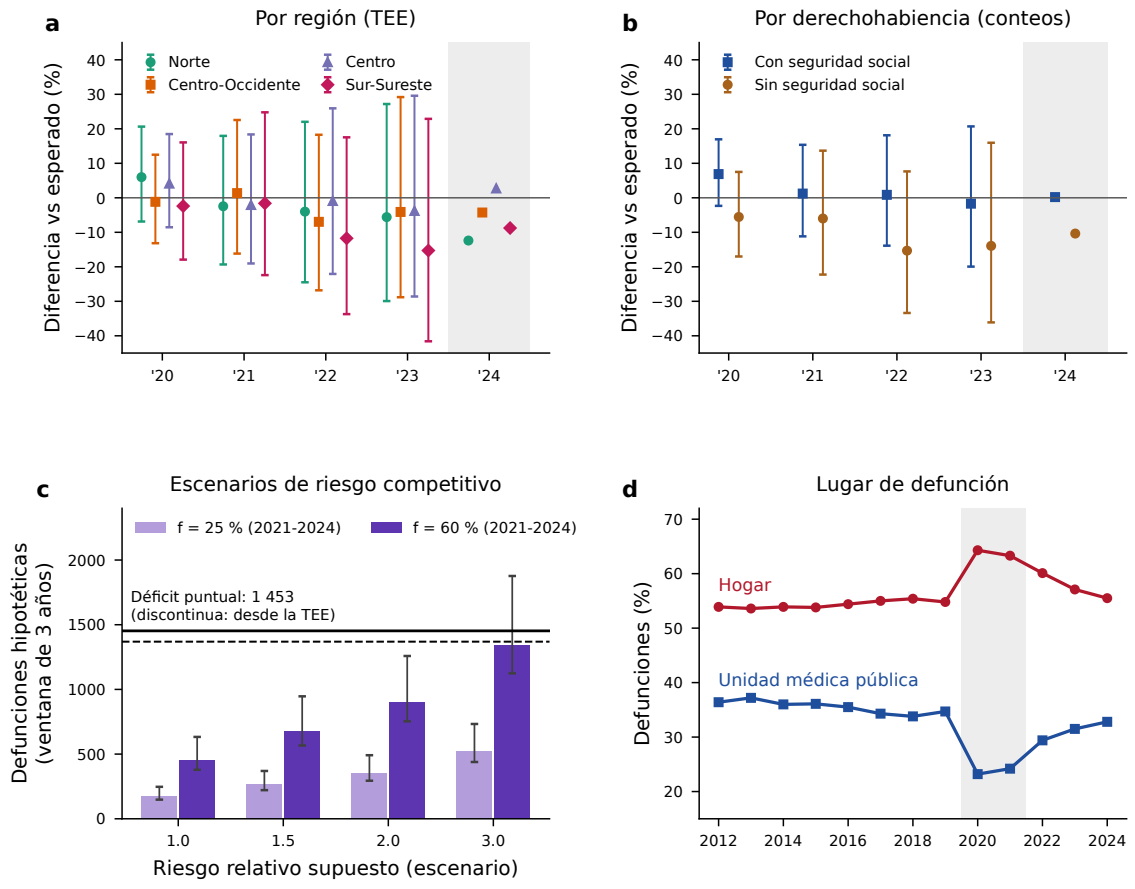

**Figura S1.** Aplicación al cáncer de mama. a: región (TEE). b: derechohabiencia (conteos). Barras: intervalo de predicción de 90 % de nivel nominal calibrado con errores de conteos del conjunto de series (2020-2023); 2024 (sombreado) solo estimación puntual. c: escenarios deterministas de defunciones por cáncer de mama adelantadas a 2021-2023 por muertes por COVID-19 (barras: escenario de referencia por riesgo relativo supuesto y fracción f; líneas de error: mínimo y máximo con las variantes de la tabla S11B), frente al déficit puntual en conteos (línea continua) y al derivado de la TEE (discontinua), cuyos intervalos anuales incluyen el cero. Son supuestos, no estimaciones. d: lugar de defunción.

In [46]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S1'))

In [47]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S11', plegada=True))

Ventana,Déficit puntual en conteos,Déficit aproximado desde la TEE,"Escenario de referencia, RR 1-3 y f 25-60 %",Todas las variantes,C50 adicional estimada en causas mal definidas vs 2017-2019,Mal definidas / déficit en conteos (%)
2021-2023 (principal),1 452.5,1 369.1,176-1 341,148-1 877,47,3.2
2021-2024 (sensibilidad),1 984.6,1 953.7,227-1 618,191-2 266,58,2.9


In [48]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S11B', plegada=True))

RR supuesto,Mujeres con cáncer de mama entre las defunciones por COVID-19 (H),"A 2021-2023, f = 25 %","A 2021-2023, f = 60 %",Intervalo con todas las variantes
1,909,176,452,148-633
1.5,1 360,264,676,221-947
2,1 808,351,899,294-1 258
3,2 697,523,1 341,439-1 877


In [49]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S11C', plegada=True))

Parámetro,Fuente,Población,Medida original,Transformación,Valores usados,Justificación / nota
"D: defunciones femeninas por COVID-19, ≥ 20 años, 2020-2022, por edad","INEGI, estadísticas de defunciones (código U07 como causa básica)",Mujeres fallecidas en México,Conteo,Ninguna,Dato observado,Registro nacional
P5: prevalencia a 5 años de cáncer de mama,"GLOBOCAN 2024, ficha de México (103 771; 154.0 por 100 000 mujeres)","Mujeres en México, 2024",Casos prevalentes a 5 años,kP = 1.00 o 0.90 para aproximar 2020-2021,Supuesto (kP),La cifra ya corresponde a mujeres; no se aplica factor por sexo
a: distribución por edad de los casos prevalentes,Aproximación con la edad de las defunciones C50 (INEGI 2017-2019),Mujeres fallecidas por C50,Proporción por grupo de edad,"a = w·(edad de las defunciones C50) + (1 − w)·(la misma, un grupo quinquenal más joven); w = 0.5 (referencia), 1 (edad de las defunciones C50) o 0 (≈ 5 años más joven)",Supuesto,Los casos prevalentes son más jóvenes que las defunciones; sin dato nacional
"RR: riesgo de morir por COVID-19, mujeres con frente a sin cáncer de mama, en la población","No se identificó una estimación directamente transferible. Zewde et al. (ref. 26): OR 1.93 y HR 1.54 de mortalidad intrahospitalaria, pacientes hospitalizados con cualquier cáncer",No equivalente,OR/HR intrahospitalarios,No se transforma (OR→RR exige un riesgo basal no disponible),"Escenarios: 1.0, 1.5, 2.0 y 3.0",1.0 = sin riesgo adicional
U: subregistro de defunciones por COVID-19,Sin fuente específica,—,—,—,U = 1.0 o 1.4,Referencia 1.0 (solo defunciones registradas)
f: fracción que habría muerto por cáncer de mama en la ventana,Sin fuente específica,—,—,f(2021-2023) = 1 − (1 − f)^(3/4) (riesgo constante),f(2021-2024) = 0.25 o 0.60,"Depende del estadio, que no se conoce"
Déficit puntual (denominador),"Este estudio: Σ(esperadas − observadas), ensamble",Mujeres ≥ 20 años,Defunciones,Ninguna,Estimación puntual,Sus intervalos anuales incluyen el cero


In [50]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S12A', plegada=True))

Código,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
1,579,522,509,519,534,481,543,569,1241,1842,1983,2209,2337
10,0,0,0,0,0,0,0,0,0,0,15,30,32
2,2489,2438,2717,2692,2811,2892,2977,3146,3350,3306,3449,3555,3700
3,561,592,602,643,644,741,741,790,814,774,791,757,818
4,65,84,65,79,75,80,86,95,97,77,76,86,81
5,28,32,33,29,38,32,40,48,49,52,36,23,30
6,18,15,22,16,16,17,15,5,20,13,12,13,14
7,1302,1348,1475,1642,1806,1861,2013,1980,1134,554,182,12,4
8,190,140,175,210,210,260,239,255,272,304,305,323,298
9,15,8,15,8,11,14,8,5,9,10,62,113,132


In [51]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S12B', plegada=True))

Grupo,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Con seguridad social,56.3,56.8,57.5,55.1,54,54.5,53.3,54.5,54.9,53.8,56.2,56.3,57.1
Otra o no especificada,9.9,9.4,9.1,10.3,10.7,11.4,11.3,11.4,14.9,15.5,15.2,14.3,12.7
Sin seguridad social,33.8,33.8,33.4,34.6,35.4,34.1,35.4,34.1,30.2,30.7,28.6,29.4,30.2


In [52]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S12C', plegada=True))

Código,2012-2017,2018-2022,2023,2024
1,Ninguna,Ninguna,Ninguna,Ninguna
2,IMSS,IMSS,IMSS,IMSS
3,ISSSTE,ISSSTE,ISSSTE,ISSSTE
4,PEMEX,PEMEX,PEMEX,PEMEX
5,SEDENA,SEDENA,SEDENA,SEDENA
6,SEMAR,SEMAR,SEMAR,SEMAR
7,Seguro popular,Seguro Popular,Reportado como equivalente al Seguro Popular,Reportado como equivalente al Seguro Popular
8,Otra,Otra,Otra,Otra
9,IMSS oportunidades,IMSS PROSPERA,IMSS BIENESTAR,IMSS BIENESTAR
10,—,—,Instituto de Seguridad Social para las Fuerzas Armadas Mexicanas (ISSFAM),Instituto de Seguridad Social para las Fuerzas Armadas Mexicanas (ISSFAM)


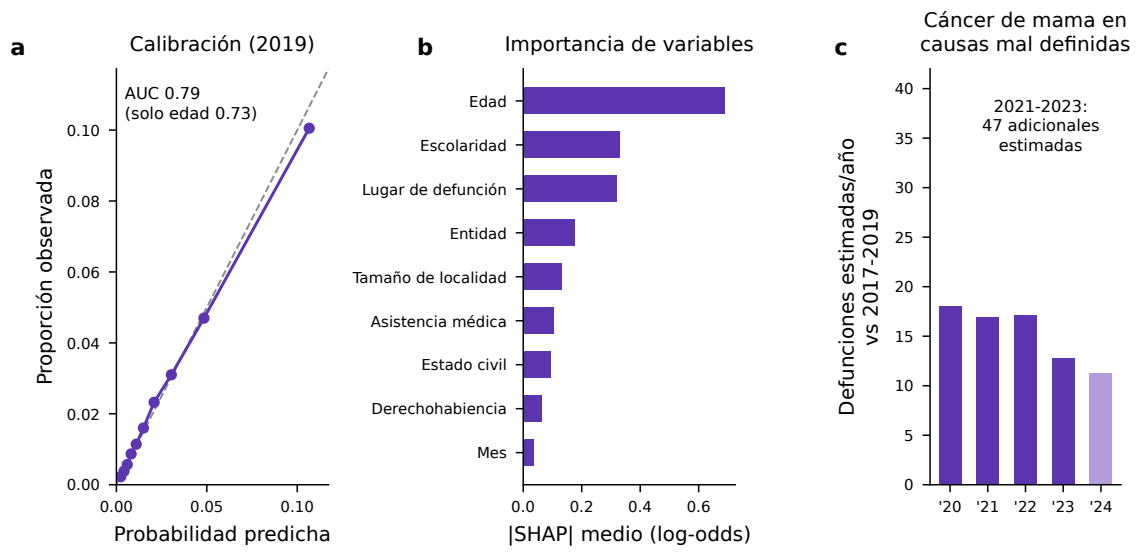

**Figura S2.** Clasificador de causa C50 aplicado a defunciones con causa mal definida. a: calibración en 2019 (defunciones con causa conocida). b: importancia de variables (SHAP). c: defunciones C50 estimadas en causas mal definidas por encima del promedio de 2017-2019 (2024 en tono claro: sensibilidad).

In [53]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S2'))

In [54]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S5', plegada=True))

Métrica,Valor
Defunciones de entrenamiento (2012-2018),1857898
Defunciones de validación (2019),300206
Proporción de C50 en validación (%),2.50
Iteraciones (parada temprana),127
AUC,0.786
"AUC, modelo solo con edad",0.728
AUPRC,0.099
"AUPRC, modelo solo con edad",0.057
Puntuación de Brier,0.023
Razón de casos predichos/observados,1.013


### Piloto histórico y recursos computacionales

El piloto S3 utiliza 1 328 series y dos orígenes. Sus resultados no son directamente comparables con el ajuste fino principal. S7 informa costos de las ejecuciones originales: leerla aquí no constituye una nueva medición de entrenamiento. S14 compara dos juegos de pronósticos guardados; los tiempos medidos por este notebook corresponden exclusivamente al recálculo actual.

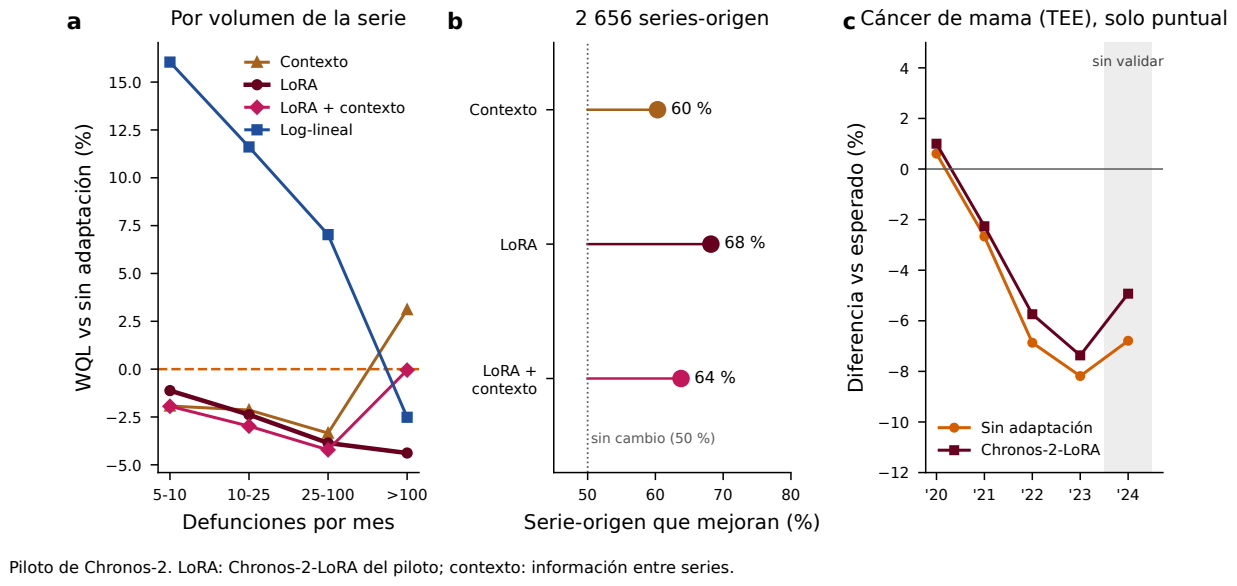

**Figura S3.** Piloto histórico de adaptación de Chronos-2: 1 328 series con media ≥ 5 defunciones/mes en 2012-2019 (estrato 5-10), con orígenes en diciembre de 2015 y diciembre de 2016. Sin adaptación: modelo original; LoRA: versión Chronos-2-LoRA del piloto; contexto: información entre series. Los resultados no se actualizaron y no son directamente comparables con la figura 6 y la tabla S4. c: solo estimaciones puntuales; 2024 (sombreado) sin validación.

In [55]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S3'))

In [56]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S7', plegada=True))

Modelo,Parámetros (millones),Entrenamiento (s),Pronóstico de 2 870 series (s)
Chronos-2,119,0 (sin entrenamiento),18
Chronos-Bolt,205,0 (sin entrenamiento),12
TimesFM-2.5,200,0 (sin entrenamiento),134
"Clásicos (4 modelos, ajuste por serie, 1 núcleo)",—,incluido en el ajuste,445 (ajuste y pronóstico)
LightGBM global,—,56,incluida
N-HiTS global,—,35,incluida
Chronos-2 + LoRA (1 000 pasos),119,984-1128,≈ 18 (como Chronos-2)
"Chronos-2, ajuste completo (1 000 pasos)",119,963,≈ 18 (como Chronos-2)


In [57]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S14', plegada=True))

Cifra,Modelo,Publicada,Nueva,Diferencia
WQL relativo al log-lineal,LightGBM global,0.867,0.867,+0.000
Cobertura 80 % (%),LightGBM global,72.1,72.1,+0.000
Falsos positivos placebo (%),LightGBM global,10.1,10.1,+0.000
Semiancho mediano placebo (%),LightGBM global,30.0,30.0,+0.000
WQL relativo al log-lineal,Ensamble (mediana),0.876,0.876,+0.000
Cobertura 80 % (%),Ensamble (mediana),82.0,82.0,+0.000
Falsos positivos placebo (%),Ensamble (mediana),8.6,8.6,+0.000
Semiancho mediano placebo (%),Ensamble (mediana),34.1,34.1,+0.000
WQL relativo al log-lineal,TimesFM-2.5,0.891,0.891,+0.000
Cobertura 80 % (%),TimesFM-2.5,79.7,79.7,+0.000


### Variantes y diagnósticos exploratorios de C50

Las figuras S4–S6 presentan variantes de tendencia, lugar y residuos. Las covarianzas robustas describen incertidumbre condicional al modelo y no eliminan autocorrelación. Los catálogos y el flujo de registros permiten revisar los universos analíticos. S19–S21 ya se mostraron con la figura 5.

In [58]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S17', plegada=True))

periodo,codigo,grupo_analitico,2012-2017,2018-2022,2023-2024,Registros C50 2012-2024
,1,Unidad pública,Secretaría de salud,Secretaría de salud,Secretaría de salud,7081
,2,Unidad pública,IMSS oportunidades,IMSS PROSPERA,IMSS BIENESTAR,343
,3,Unidad pública,IMSS,IMSS,IMSS,16184
,4,Unidad pública,ISSSTE,ISSSTE,ISSSTE,3578
,5,Unidad pública,PEMEX,PEMEX,PEMEX,402
,6,Unidad pública,Secretaría de la defensa nacional,Secretaría de la Defensa Nacional,Secretaría de la Defensa Nacional (SEDENA),277
,7,Unidad pública,Secretaría de marina,Secretaría de Marina,Secretaría de Marina (SEMAR),118
,8,Unidad pública,Otra unidad pública,Otra unidad pública,Otra unidad pública,1534
,9,Unidad privada,Unidad médica privada,Unidad médica privada,Unidad médica privada,5050
,10,Otro/NE,Vía pública,Vía pública,Vía pública,120


In [59]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S18', plegada=True))

Año de ocurrencia,Defunciones,Mismo año (%),Año siguiente (%),≥ 2 años (%)
2012,5610,98.38,1.35,0.27
2013,5562,98.08,1.58,0.34
2014,5985,98.46,1.34,0.2
2015,6273,98.33,1.36,0.32
2016,6643,98.57,1.2,0.23
2017,6905,97.78,1.94,0.28
2018,7245,98.05,1.74,0.21
2019,7495,98.31,1.43,0.27
2020,7886,97.44,2.26,0.3
2021,7845,97.96,1.89,0.15


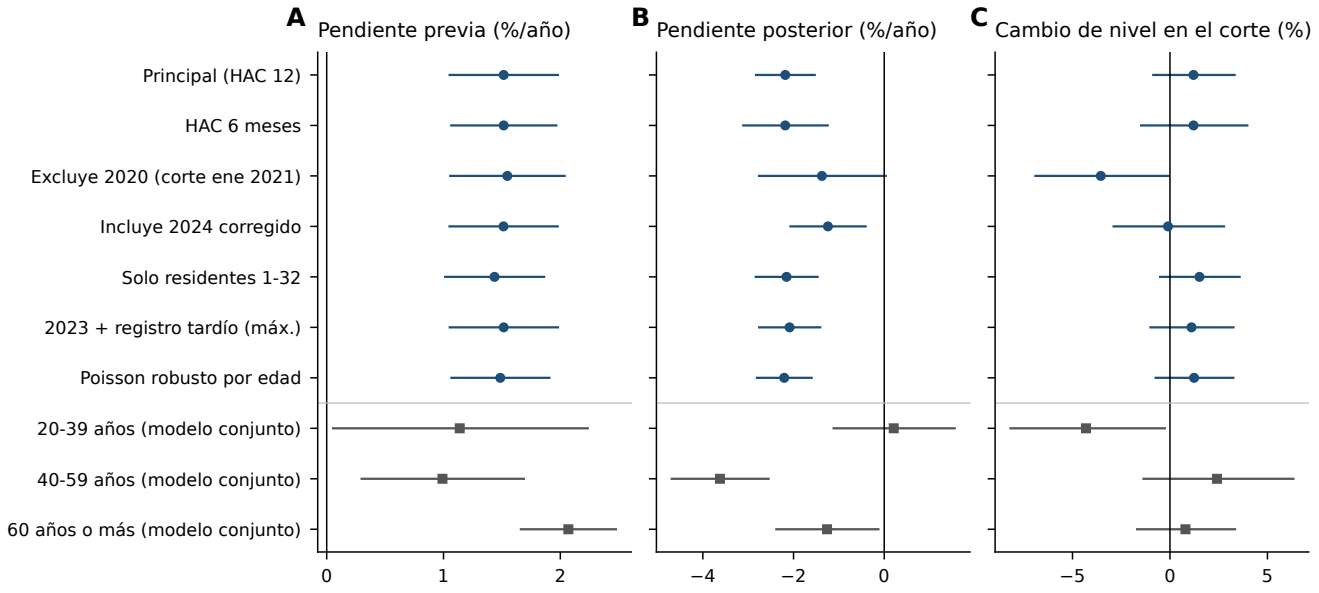

**Figura S4.** Variantes del análisis de tendencia de la TEE de cáncer de mama (IC 95 % de parámetros de la trayectoria, no intervalos de predicción). a: pendiente anual previa a marzo de 2020. b: pendiente anual posterior. c: cambio de nivel en el corte. Círculos: serie nacional; cuadrados: grupos de edad en el modelo conjunto con covarianza de Driscoll-Kraay. La tabla S19 reúne todas las variantes ejecutadas.

In [60]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S4'))

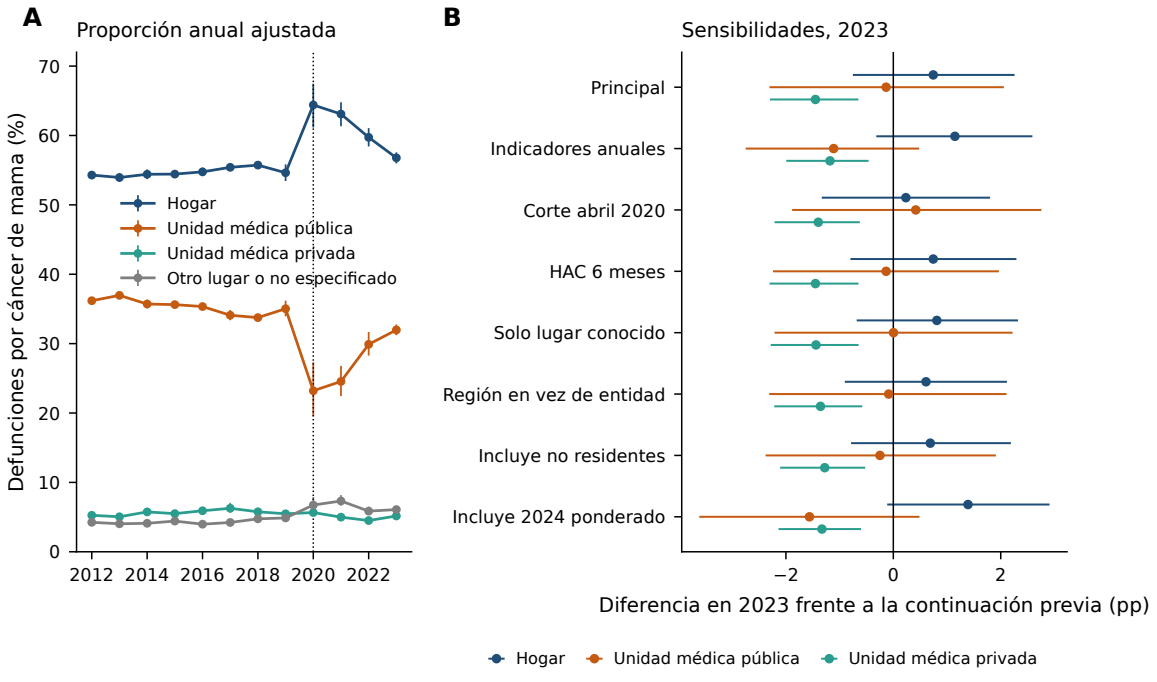

**Figura S5.** Lugar de defunción por cáncer de mama. a: proporción anual ajustada por edad quinquenal, entidad y mes (IC 95 %), 2012-2023. b: diferencia en 2023 frente a la continuación de la tendencia previa en las sensibilidades prefijadas (puntos porcentuales, IC 95 %; tabla S22).

In [61]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S5'))

In [62]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S22', plegada=True))

periodo,analisis,desenlace,2023,mar-dic 2020
,anual_post,Hogar,1.1 (-0.3 a 2.6),11.3 (9.9 a 12.6)
,anual_post,Unidad privada,-1.2 (-2.0 a -0.5),-0.6 (-1.1 a -0.1)
,anual_post,Unidad pública,-1.1 (-2.7 a 0.5),-13.2 (-14.9 a -11.4)
,principal,Hogar,0.7 (-0.8 a 2.3),11.0 (9.7 a 12.3)
,principal,Unidad privada,-1.5 (-2.3 a -0.7),-0.9 (-1.5 a -0.3)
,principal,Unidad pública,-0.1 (-2.3 a 2.1),-12.6 (-14.5 a -10.6)
,sens_2024_ponderado_completitud,Hogar,1.4 (-0.1 a 2.9),10.7 (9.3 a 12.1)
,sens_2024_ponderado_completitud,Unidad privada,-1.3 (-2.1 a -0.6),-0.9 (-1.6 a -0.4)
,sens_2024_ponderado_completitud,Unidad pública,-1.6 (-3.6 a 0.5),-11.9 (-14.2 a -9.6)
,sens_2024_sin_ponderar,Hogar,1.4 (-0.1 a 3.0),10.6 (9.2 a 12.1)


In [63]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S23', plegada=True))

anio,Hogar,Otro/NE,Unidad privada,Unidad pública,TEE Hogar,TEE Unidad médica (pública + privada),TEE Otro/NE,TEE Total
2012,54.3 (53.9 a 54.7),4.2 (4.0 a 4.6),5.3 (5.0 a 5.6),36.2 (35.7 a 36.7),8.95,6.9,0.7,16.56
2013,53.9 (53.3 a 54.6),4.0 (3.5 a 4.7),5.0 (4.7 a 5.4),37.0 (36.4 a 37.5),8.57,6.72,0.64,15.94
2014,54.4 (53.7 a 55.1),4.1 (4.0 a 4.3),5.7 (5.4 a 6.2),35.7 (35.1 a 36.3),8.97,6.95,0.67,16.59
2015,54.4 (53.9 a 55.0),4.4 (4.2 a 4.7),5.5 (5.4 a 5.7),35.6 (35.2 a 36.1),9.16,7.03,0.74,16.93
2016,54.8 (54.1 a 55.4),4.0 (3.8 a 4.2),5.9 (5.7 a 6.2),35.3 (34.9 a 35.8),9.51,7.21,0.69,17.41
2017,55.4 (54.9 a 55.9),4.2 (4.0 a 4.5),6.3 (5.6 a 7.1),34.1 (33.4 a 34.8),9.67,7.11,0.75,17.54
2018,55.7 (55.3 a 56.2),4.7 (4.5 a 5.1),5.8 (5.6 a 6.0),33.7 (33.2 a 34.3),9.91,7.1,0.85,17.86
2019,54.6 (53.4 a 55.8),4.9 (4.7 a 5.1),5.5 (5.3 a 5.7),35.0 (33.9 a 36.2),9.85,7.2,0.89,17.94
2020,64.4 (61.2 a 67.5),6.7 (5.8 a 7.9),5.7 (5.4 a 6.0),23.2 (19.5 a 27.3),11.84,5.3,1.24,18.39
2021,63.1 (61.3 a 64.8),7.3 (6.7 a 8.2),5.0 (4.7 a 5.4),24.5 (22.4 a 26.8),11.34,5.21,1.33,17.88


In [64]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S24', plegada=True))

lugar,autocorrelacion_1,"Ljung-Box, p (6)","Ljung-Box, p (12)","Ljung-Box, p (24)"
Hogar,0.213155,0.0748418,0.173008,0.172853
Otro/NE,0.216944,0.00267775,0.0428931,0.0476033
Total,0.0633596,0.61731,0.44328,0.172059
Unidad médica (pública + privada),0.105926,0.0883176,0.00136656,0.00378344


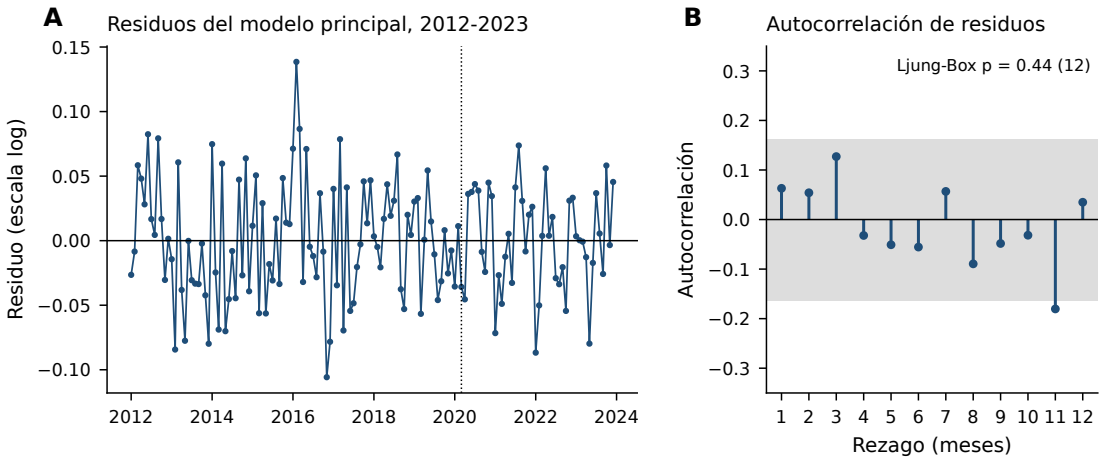

**Figura S6.** Diagnóstico del modelo principal de tendencia. a: residuos mensuales en escala logarítmica (línea punteada: marzo de 2020). b: autocorrelación de los residuos (banda: ± 1.96/√144).

In [65]:
inventario.append(mostrar_figura(REPO, SALIDA, 'S6'))

### Tablas documentales

S13 y S16 son transcripciones estructuradas del suplemento, presentadas con Python. No se derivan de estimaciones estadísticas. S16 conserva las **52 entradas** de la adaptación TRIPOD+AI realizada por los autores; no se presenta como la lista oficial íntegra. Las versiones históricas de modelos indicadas en S13 corresponden al análisis original, no a las dependencias necesarias para este recálculo.

In [66]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S13', plegada=True))

Aspecto,Evaluación comparativa,Aplicación al cáncer de mama
Series,Conteos mensuales (2 870),TEE mensual y conteos de cáncer de mama (11 series)
Transformación (clásicos),log(y + 1); ingenuo en escala original (truncado en 0),log(y); ingenuo en escala original
Trayectorias simuladas,500,2 000
Pronóstico puntual,Cuantil 0.5 de cada modelo,Clásicos: media retransformada; fundacionales: mediana; ensamble: mediana de los puntos
Semillas (publicado),Por serie; SARIMA y ETS sin semilla,default_rng(2026); SARIMA y ETS sin semilla
"Semillas (nueva ejecución, tabla S14)",SARIMA: default_rng(i); ETS: default_rng(i + 1),SARIMA y ETS: default_rng(entero extraído de default_rng(2026))
Versiones,amazon/chronos-2 y amazon/chronos-bolt-base (chronos-forecasting 2.3.2); google/timesfm-2.5-200m-pytorch (timesfm 3.0.2); LightGBM 4.7.0; neuralforecast 3.2.2; statsmodels 0.15.0,Mismos modelos fundacionales y statsmodels
Edad,"0-39, 40-64 y ≥ 65 años (todas las edades)","Mujeres ≥ 20 años; 20-39, 40-59 y ≥ 60 años"
Fallos,Sustitución por log-lineal (0 casos),Sin sustitución (0 fallos)
Orígenes de validación,3 anuales (36 meses) + 2 (48 meses),9 trimestrales (36 meses) + 5 (48 meses)


In [67]:
inventario.append(mostrar_tabla(REPO, SALIDA, DATOS, tablas, 'S16', plegada=True))

Sección (TRIPOD+AI),Ítem,Aplicabilidad,Dónde se informa / justificación
Título,1,Aplica,"Título: IA, mortalidad esperada, evaluación comparativa y aplicación al cáncer de mama."
Resumen,2,Aplica (adaptado),Resumen estructurado según GMM; la lista TRIPOD+AI para resúmenes no se aplicó ítem por ítem.
Antecedentes,3a,Aplica,Introducción: contexto y modelos clásicos habituales.
Antecedentes,3b,Aplica (adaptado),Propósito: vigilancia poblacional de la mortalidad; usuarios: analistas de salud pública; no hay uso clínico individual.
Antecedentes,3c,Aplica (adaptado),Diferencias por región y derechohabiencia descritas (resultados; tabla S12); sin análisis formal de desigualdades.
Objetivos,4,Aplica,"Introducción, último párrafo (evaluación de modelos y aplicación)."
Datos,5a,Aplica,"INEGI, WPP 2024 y Censo 2020 (métodos; S10). S11a: microdatos C50 y reconstrucción de las series."
Datos,5b,Aplica,2012-2024; orígenes de validación de 2014 a 2016 y de aplicación en 2019 (figura 1). S11: lugar 2012-2023; 2024 solo sensibilidad y tasas observadas.
Participantes,6a,Aplica (adaptado),"Ámbito nacional y 32 entidades; unidades: series agregadas, no centros ni individuos."
Participantes,6b,Aplica (adaptado),"Criterios de inclusión de series y de registros (métodos; tabla S1; S10). S11a-b: mujeres ≥ 20 años, mes válido y residencia según análisis."


<a id="balance"></a>
## 8. Comprobaciones, procedencia y límites

Esta última sección coteja las cifras principales, la cobertura documental y las comparaciones con las referencias. Las discrepancias de comparación se muestran y registran sin convertirlas en coincidencias; los errores de ejecución de un análisis detienen el recorrido. Un resultado guardado se identifica como tal y nunca cuenta como entrenamiento repetido. Los informes preservan las tolerancias originales de comparación; las excepciones editoriales o de auditoría se verifican con las reglas existentes del repositorio. En la validación de este entorno Linux se observaron diferencias pequeñas en el diagnóstico de convergencia `score_max_abs` de cuatro archivos C50; se conservan explícitamente como discrepancias. Las cifras del manuscrito se cotejan de forma independiente en la celda siguiente.

In [68]:
numeros = cargar_json(B / "resultados/numeros_v9.json")
deteccion_ensamble = numeros["p2"]["D1"]["Ensamble (mediana)"]["det20"]
deteccion_loglineal = numeros["p2"]["D1"]["Log-lineal"]["det20"]
assert round(deteccion_ensamble, 1) == 22.2
assert round(deteccion_loglineal, 1) == 17.1
for anio, esperado in [(2022, -6.3), (2023, -7.8)]:
    fila = nacional[nacional.year == anio].iloc[0]
    assert round(fila.pscore, 1) == esperado
    assert fila.lo_todas <= 0 <= fila.hi_todas
comprobaciones = pd.DataFrame([
    {"Comprobación":"Series del corpus", "Valor":len(corpus)},
    {"Comprobación":"Detección +20 %, ensamble (%)", "Valor":round(deteccion_ensamble, 1)},
    {"Comprobación":"Detección +20 %, log-lineal (%)", "Valor":round(deteccion_loglineal, 1)},
    {"Comprobación":"APVP 2023", "Valor":apvp_2023},
    {"Comprobación":"APVP en 40–59 años (%)", "Valor":round(aporte_40_59, 1)},
    {"Comprobación":"Hogar rural, 2023 (%)", "Valor":round(local_2023.loc["< 2 500", "Hogar %"], 1)},
    {"Comprobación":"Hogar ≥100 000 habitantes, 2023 (%)", "Valor":round(local_2023.loc["≥ 100 000", "Hogar %"], 1)},
])
display(comprobaciones)
comprobaciones.to_csv(SALIDA / "comprobaciones_manuscrito.csv", index=False)

,Comprobación,Valor
0,Series del corpus,2870.0
1,"Detección +20 %, ensamble (%)",22.2
2,"Detección +20 %, log-lineal (%)",17.1
3,APVP 2023,120893.0
4,APVP en 40–59 años (%),65.2
5,"Hogar rural, 2023 (%)",70.2
6,"Hogar ≥100 000 habitantes, 2023 (%)",53.0


In [69]:
registro = cerrar_reproduccion(REPO, SALIDA, DATOS, antes, inventario)
# Inventario con rutas, hashes, fuentes y código: CSV/JSON en la carpeta de salida.
display(HTML('<p><a href="../' + str(Path(os.path.relpath(SALIDA, REPO))) + '/inventario_reproduccion.csv">Inventario completo de reproducción</a></p>'))

,Módulo,identico_bytes,coincide_tolerancia,identico_contenido,sin_referencia_conocido_verificado,difiere_conocido_verificado,difiere,no_generado_conocido_verificado
0,benchmark,57,6,4.0,1.0,1,0.0,0.0
1,c50,12,25,0.0,0.0,1,4.0,1.0


,Productos presentados
estado,
documental,3
recalculado,46
regenerado desde resultados guardados,8


Cobertura completa: 57 productos. Entradas y referencias intactas.
Las excepciones conocidas se verificaron con las reglas existentes; no se ampliaron tolerancias.


,archivo,tipo_campo,diferencias,diferencia_absoluta_maxima
0,c50/resultados/lugar_defuncion.json,score_max_abs,35,3.843065e-10
1,c50/resultados/numeros_v11.json,score_max_abs,36,5.378013e-09
2,c50/resultados/tendencia_ampliaciones.json,score_max_abs,1,5.378013e-09
3,c50/tablas/tablaS_lugar_diagnosticos.csv,score_max_abs,34,3.843065e-10


Consulte discrepancias_detalladas.csv: conserva cada campo y los dos valores, con las tolerancias originales.


### Qué permite comprobar esta ejecución

- La integridad de entradas y referencias, la ejecución completa de los análisis disponibles y la presentación de las 12 figuras y 45 tablas del inventario documental.
- La reconstrucción de los resultados del benchmark desde pronósticos guardados y de los análisis C50 desde el extracto distribuido, con sus comparaciones numéricas.
- El origen de cada producto, los comandos, versiones, tiempos y discrepancias en `registro_notebook.json`, `entornos.json`, los archivos `requirements_ejecutados_*.txt` y los registros por etapa.

### Límites de reproducibilidad

Los NPZ y los backtests de la aplicación a mama son insumos de etapas previas; no se vuelven a generar. Tampoco se repiten el entrenamiento de modelos, el ajuste fino, el piloto histórico ni ciertas etapas auxiliares sin generador recuperado. La revisión exacta de algunos pesos originales es desconocida. La reproducción aquí comienza desde los paquetes procesados; no reconstruye todo el corpus a partir de los microdatos nacionales completos del INEGI.

Las figuras conservan valores y artistas numéricos al actualizar sus rótulos. La tipografía y el render pueden diferir de macOS; los hashes de PDF incluyen metadatos y no son una prueba de equivalencia científica. La comparación del PNG histórico de S2 se registra como control tipográfico, separada de la equivalencia numérica.

Los análisis C50 son exploratorios y ecológicos. Los IP nominales de mama, los IC de modelos de tendencia y lugar, y los escenarios hipotéticos de desplazamiento temporal responden a preguntas distintas. Ninguno identifica por sí mismo un efecto causal de la pandemia.

### Referencias, datos y cita

La [matriz de trazabilidad](../docs/MATRIZ_TRAZABILIDAD.csv), la [guía técnica de reproducción](../docs/REPRODUCCION.md) y la [documentación de entrenamiento](../docs/ENTRENAMIENTO.md) amplían su procedencia. Para citar el software use [CITATION.cff](../CITATION.cff); las condiciones de uso se indican en [LICENCIAS.md](../LICENCIAS.md). Los DOI de software y datos están en el [README](../README.md).

[Volver al índice](#indice)